# NB-02 · Stage 3 - DEAN supervised fine-tuning (flat baseline, revision 2)

**Project:** hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, GPU T4, internet not required

This notebook turns the self-supervised DEAN encoder from NB-01 into the flat 26-label classifier that every later tier has to beat, and then freezes it as the teacher.

The first version of this notebook stopped at epoch 14 of a 50-epoch schedule, so the learning rate never decayed. It also overfitted after epoch 8, its probabilities were over-confident (ECE 0.07 to 0.13), and the teacher outputs that were cached for distillation came from the very records the teacher had trained on. This revision addresses those problems directly:

* a schedule that actually finishes (20 epochs), with an exponential moving average of the weights, stronger augmentation, mixup and label smoothing;
* model selection on validation macro-AUC instead of the noisy tuned-threshold F1;
* per-label Platt calibration fitted on fold 9, with an honest cross-fitted ECE;
* the same fine-tuning run from a random-init encoder, so the value of SSL can be stated after fine-tuning and not only for a frozen probe;
* out-of-fold teacher logits for the training records, plus a measured confidence gap between in-sample, out-of-fold and validation predictions;
* one reliability threshold (10 validation positives) used everywhere.

### Input
| Kaggle Dataset | Files used |
|---|---|
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| `dean-ssl-pretrained-v1` (NB-01) | `dean_lib.py`, `dean_encoder_ssl.pt`, `dean_config.json` |
| *(only when resuming)* `dean-ft-resume` | `ckpt/ft_*_last.pt`, `randft_*`, `oof_group*.npz` from the earlier session |

### Output (`/kaggle/working`)
| File | Used by |
|---|---|
| `dean_finetuned.pt` | NB-03 to NB-11 (encoder, head, calibration, thresholds, label order, normalisation) |
| `calibration.json` | every notebook that turns teacher logits into probabilities |
| `dean_logits_train_oof.npy`, `dean_logits_train.npy`, `dean_logits_val.npy` | NB-05 onwards (use the out-of-fold file as the training target) |
| `dean_emb_{train,val}.npy`, `dean_tokens_{train,val}_fp16.npy`, `split_idx.npz` | NB-03 (gating), NB-04 (prototypes), NB-05 (token-level distillation) |
| `baseline_metrics.json`, `val_metrics_table.csv/.tex`, `probe_results.csv`, `ablation_ssl.csv` | paper tables, reference for every later tier |
| `eval_lib.py` | every later notebook |
| `figures/*.png, *.pdf` | paper figures |

Fold usage: folds 1-8 train, fold 9 validation (model selection, calibration, thresholds), **fold 10 is not loaded anywhere here**. The flat-DEAN test numbers are computed once, in NB-09.

Order of work: setup, config, artefacts, data, model and scan, smoke test, linear probe, fine-tuning, calibration and validation, figures, random-init baseline, out-of-fold teacher, cache and export.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()                      # one clock for the whole notebook, used by the time budget

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')   # lets us dry-run off Kaggle
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
CKPT_DIR = os.path.join(WORK, 'ckpt')
FIG_DIR = os.path.join(WORK, 'figures')
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if ON_KAGGLE:
    assert dev.type == 'cuda', 'No GPU. Settings -> Accelerator -> GPU T4.'
USE_AMP = dev.type == 'cuda'
if USE_AMP:
    torch.backends.cudnn.benchmark = True

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if USE_AMP: torch.cuda.manual_seed_all(s)

def find_art(name):
    # first match in the working directory, then in any attached Dataset
    hits = sorted(glob.glob(f'{WORK}/**/{name}', recursive=True)) + sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True))
    return hits[0] if hits else None

def hours_left(max_hours):
    return max_hours - (time.time() - NB_T0) / 3600

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__,
            'pandas': pd.__version__}
print(VERSIONS)
print('device', dev, '|', torch.cuda.get_device_name(0) if USE_AMP else 'cpu', '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'}
device cuda | Tesla T4 | work /kaggle/working


## 1. Configuration
What changed with respect to the first run, and why:

* **20 epochs, 2 warm-up epochs, patience 8.** The cosine schedule is now meant to be completed. In the first run the best epoch was 8 and the run stopped at 14, with the learning rate still near its peak.
* **Weights are averaged (EMA, decay 0.999).** The EMA copy is the one that is validated, selected and exported. With about 545 steps per epoch the averaging horizon is roughly two epochs, which smooths exactly the epoch-to-epoch jitter we saw.
* **Regularisation:** weight decay 0.05, augmentation (amplitude jitter, baseline wander, noise, lead dropout, time shift), mixup on 30% of the batches, and a small label smoothing in the BCE term.
* **Selection metric is validation macro-AUC** over labels with at least 10 validation positives. Threshold-tuned macro-F1 on 2,183 records moves too much from one epoch to the next.
* **Learning rates stay at 5e-5 (backbone) and 5e-4 (head).** The plan file says 1e-5 and 1e-4, which would barely move an encoder that had only 25 SSL epochs. This is still a one-line change if you want it as a sweep point.
* **One reliability rule:** labels with fewer than 10 validation positives are shown in every table and figure but excluded from macro averages and from model selection.
* **Optional stages** (random-init fine-tune, out-of-fold teacher) can be switched off with `run_random_ft` and `run_oof`. The smoke test prints the projected hours for each.

In [2]:
CFG = dict(
    seed=42,
    min_pos_select=10, min_pos_report=10,          # same rule for selection and reporting
    # linear probe (cached embeddings, cheap)
    head_drop=0.2, probe_epochs=60, probe_lr=1e-3, probe_wd=1e-2, probe_bs=256,
    # fine-tuning
    epochs=30, batch_size=32, lr_backbone=5e-5, lr_head=5e-4, wd=0.05,
    warmup_epochs=3, lr_floor=0.02, clip=1.0, patience=10, ema_decay=0.999,
    grad_ckpt=False,                               # the smoke test switches it on by itself if memory runs out
    # loss: sigmoid-F1 + BCE with capped positive weights
    pos_weight_cap=100.0, f1_weight=1.0, bce_weight=1.0, f1_beta=6.0, label_smooth=0.01,
    # regularisation
    aug_strength=1.0, mixup_prob=0.3, mixup_alpha=0.4,
    select_metric='auc',                           # 'auc' or 'f1'
    save_every=2, max_hours=10.5,
    n_boot=300,
    # optional stages
    run_random_ft=True,
    run_oof=True, oof_epochs=12, oof_patience=4,
)
print({k: CFG[k] for k in ['epochs', 'batch_size', 'lr_backbone', 'lr_head', 'wd', 'ema_decay', 'select_metric', 'run_random_ft', 'run_oof']})

{'epochs': 30, 'batch_size': 32, 'lr_backbone': 5e-05, 'lr_head': 0.0005, 'wd': 0.05, 'ema_decay': 0.999, 'select_metric': 'auc', 'run_random_ft': True, 'run_oof': True}


## 2. Shared evaluation library
Written to `eval_lib.py` so that NB-03 to NB-11 compute metrics, thresholds, calibration and bootstrap intervals with exactly the same code. New in this version: Platt calibration, a cross-fitted ECE (calibration is fitted on one half of the validation fold and scored on the other half, so the number is not flattered), and a paired bootstrap for the difference between two models.

In [3]:
%%writefile eval_lib.py
import warnings
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings('ignore', category=RuntimeWarning)
THR_GRID = np.round(np.arange(0.02, 0.99, 0.02), 2)


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def auc_per_label(Y, S, min_pos=5):
    out = np.full(Y.shape[1], np.nan)
    n = Y.sum(0)
    for j in range(Y.shape[1]):
        if min_pos <= n[j] < len(Y):
            out[j] = roc_auc_score(Y[:, j], S[:, j])
    return out


def _f1_counts(Y, pred):
    tp = (pred & (Y > 0)).sum(0).astype(float)
    fp = pred.sum(0) - tp
    fn = (Y > 0).sum(0) - tp
    return tp, fp, fn


def f1_at(Y, S, thr):
    # per-label F1 at fixed thresholds; nan where a label has no positives
    tp, fp, fn = _f1_counts(Y, S >= np.asarray(thr)[None])
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    f1[(Y > 0).sum(0) == 0] = np.nan
    return f1


def tune_thresholds(Y, S, grid=THR_GRID):
    # one threshold per label, picked on the data given (call this on validation only)
    pred = S[:, :, None] >= grid[None, None, :]
    pos = Y[:, :, None] > 0
    tp = (pred & pos).sum(0).astype(float)
    fp = pred.sum(0) - tp
    fn = pos.sum(0) - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    best = f1.argmax(1)
    thr = grid[best].copy()
    f1b = f1[np.arange(len(best)), best]
    nopos = (Y > 0).sum(0) == 0
    thr[nopos] = 0.5
    f1b[nopos] = np.nan
    return thr, f1b


def summarize(Y, S, min_pos):
    # macro AUC and macro F1 (val-tuned thresholds) over labels with >= min_pos positives
    thr, f1 = tune_thresholds(Y, S)
    auc = auc_per_label(Y, S, min_pos)
    mask = Y.sum(0) >= min_pos
    m_auc = float(np.nanmean(auc[mask])) if mask.any() else float('nan')
    m_f1 = float(np.nanmean(f1[mask])) if mask.any() else float('nan')
    return dict(macro_auc=m_auc, macro_f1=m_f1), thr, auc, f1


def bootstrap(Y, S, thr, min_pos=10, n_boot=300, seed=0, n_super=5):
    # resample records; thresholds stay fixed (they are not re-tuned per resample)
    rng = np.random.default_rng(seed)
    N, L = Y.shape
    aucs = np.full((n_boot, L), np.nan)
    f1s = np.full((n_boot, L), np.nan)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        aucs[b] = auc_per_label(Y[idx], S[idx], 1)
        f1s[b] = f1_at(Y[idx], S[idx], thr)
    mask = Y.sum(0) >= min_pos
    sup = mask.copy(); sup[n_super:] = False
    sub = mask.copy(); sub[:n_super] = False

    def ci(v):
        return [float(np.nanmean(v)), float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
    out = {'macro_auc': ci(np.nanmean(aucs[:, mask], 1)), 'macro_f1': ci(np.nanmean(f1s[:, mask], 1))}
    if sup.any(): out['super_auc'] = ci(np.nanmean(aucs[:, sup], 1))
    if sub.any(): out['sub_auc'] = ci(np.nanmean(aucs[:, sub], 1))
    out['label_auc_lo'] = np.nanpercentile(aucs, 2.5, axis=0)
    out['label_auc_hi'] = np.nanpercentile(aucs, 97.5, axis=0)
    return out


def paired_delta(Y, S1, S2, min_pos=10, n_boot=300, seed=0):
    # macro-AUC(S1) - macro-AUC(S2) with a paired bootstrap over records; labels with >= min_pos positives
    rng = np.random.default_rng(seed)
    cols = np.where(Y.sum(0) >= min_pos)[0]
    N = len(Y)
    d = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        a1 = auc_per_label(Y[idx][:, cols], S1[idx][:, cols], 1)
        a2 = auc_per_label(Y[idx][:, cols], S2[idx][:, cols], 1)
        d[b] = np.nanmean(a1) - np.nanmean(a2)
    return [float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))]


def per_label_table(names, Y, S, thr, min_pos=10):
    auc = auc_per_label(Y, S, 1)
    f1 = f1_at(Y, S, thr)
    pred = S >= np.asarray(thr)[None]
    tp, fp, fn = _f1_counts(Y, pred)
    rows = []
    for j, n in enumerate(names):
        npos = int(Y[:, j].sum())
        ap = average_precision_score(Y[:, j], S[:, j]) if 0 < npos < len(Y) else np.nan
        rows.append(dict(label=n, n_pos=npos, auc=auc[j], ap=ap, f1=f1[j], threshold=float(thr[j]),
                         precision=tp[j] / max(tp[j] + fp[j], 1), recall=tp[j] / max(tp[j] + fn[j], 1),
                         reliable=bool(npos >= min_pos)))
    return pd.DataFrame(rows)


def reliability(y, p, bins=10):
    # equal-mass bins, returns (mean confidence, observed frequency, ECE)
    order = np.argsort(p)
    chunks = [c for c in np.array_split(order, bins) if len(c)]
    conf = np.array([p[c].mean() for c in chunks])
    acc = np.array([y[c].mean() for c in chunks])
    w = np.array([len(c) for c in chunks]) / len(p)
    return conf, acc, float((w * np.abs(conf - acc)).sum())


def fit_platt(z, y, C=10.0):
    # p = sigmoid(a * z + b); a is kept positive so the ranking (and therefore the AUC) never changes
    from sklearn.linear_model import LogisticRegression
    z = np.asarray(z, dtype=np.float64).reshape(-1, 1)
    lr = LogisticRegression(C=C, max_iter=1000).fit(z, np.asarray(y).astype(int))
    return max(float(lr.coef_[0, 0]), 0.05), float(lr.intercept_[0])


def fit_calibration(Z, Y, min_pos=10):
    # one (a, b) per label with enough positives; the rarer labels share one pooled (a, b)
    L = Z.shape[1]
    n = Y.sum(0)
    a, b = np.ones(L), np.zeros(L)
    rich = n >= min_pos
    for j in np.where(rich)[0]:
        a[j], b[j] = fit_platt(Z[:, j], Y[:, j])
    poor = (n > 0) & ~rich
    if poor.any():
        a[poor], b[poor] = fit_platt(Z[:, poor].reshape(-1), Y[:, poor].reshape(-1))
    return a, b


def crossfit_ece(Z, Y, min_pos=10, seed=0, bins=5):
    # fit on one half, score on the other (both directions); returns raw and calibrated ECE per label
    rng = np.random.default_rng(seed)
    perm = rng.permutation(len(Z))
    halves = [perm[:len(Z) // 2], perm[len(Z) // 2:]]
    L = Z.shape[1]
    raw, cal = np.zeros((2, L)), np.zeros((2, L))
    for k, (fit, test) in enumerate([(halves[0], halves[1]), (halves[1], halves[0])]):
        a, b = fit_calibration(Z[fit], Y[fit], max(2, min_pos // 2))
        for j in range(L):
            if Y[test, j].sum() == 0:
                raw[k, j] = cal[k, j] = np.nan
                continue
            raw[k, j] = reliability(Y[test, j], sigmoid(Z[test, j]), bins)[2]
            cal[k, j] = reliability(Y[test, j], sigmoid(Z[test, j] * a[j] + b[j]), bins)[2]
    keep = Y.sum(0) >= min_pos
    raw, cal = np.nanmean(raw, 0), np.nanmean(cal, 0)
    raw[~keep], cal[~keep] = np.nan, np.nan
    return raw, cal

Writing eval_lib.py


In [4]:
import importlib
sys.path.insert(0, WORK)
import eval_lib
importlib.reload(eval_lib)
from eval_lib import (sigmoid, auc_per_label, f1_at, tune_thresholds, summarize, bootstrap, paired_delta,
                      per_label_table, reliability, fit_calibration, crossfit_ece)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False, 'pdf.fonttype': 42,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
FAMILY = {  # subclass -> parent superclass (NORM and STTC parents are their own columns)
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI',
    'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    plt.show()

## 3. NB-01 artefacts
Finds `dean_lib.py` and the SSL weights in the attached Datasets and reads the encoder configuration, the normalisation statistics and the label order from them. Nothing about the architecture is typed in again here, so a better SSL encoder from a later run drops in without edits.

In [5]:
def find_one(name):
    p = find_art(name)
    if p is None:
        raise FileNotFoundError(f'{name} not found. Attach the Dataset that contains it.')
    return p

lib_src = find_one('dean_lib.py')
if os.path.abspath(lib_src) != os.path.join(WORK, 'dean_lib.py'):
    shutil.copy(lib_src, os.path.join(WORK, 'dean_lib.py'))
import dean_lib
importlib.reload(dean_lib)
from dean_lib import DEANEncoder, count_params, embed_all
print('dean_lib from', lib_src, '| cuda mamba kernels:', dean_lib.USE_CUDA_MAMBA)

ssl_path = find_one('dean_encoder_ssl.pt')
ssl_ckpt = torch.load(ssl_path, map_location='cpu', weights_only=False)
ENC_CFG = ssl_ckpt['enc_config']
SSL_KEY = ssl_ckpt['recommended']
MU = np.array(ssl_ckpt['norm_mean'], dtype=np.float32)
SD = np.array(ssl_ckpt['norm_std'], dtype=np.float32)
print('ssl weights:', ssl_path, '| key', SSL_KEY, '| epochs', ssl_ckpt['epochs_done'])
print('encoder config:', ENC_CFG)

try:
    LABELS = json.load(open(find_one('dean_config.json')))['label_columns']
except Exception as e:
    print('dean_config.json label list not usable, falling back to csv order:', e)
    LABELS = None

def build_encoder(grad_ckpt=None):
    c = dict(ENC_CFG)
    if grad_ckpt is not None:
        c['grad_ckpt'] = grad_ckpt
    return DEANEncoder(**c)

D_MODEL = ENC_CFG['d_model']

dean_lib from /kaggle/input/datasets/iaadidev/results-stage-2-hidmamba/dean_lib.py | cuda mamba kernels: False
ssl weights: /kaggle/input/datasets/iaadidev/results-stage-2-hidmamba/dean_encoder_ssl.pt | key encoder | epochs 25
encoder config: {'in_ch': 12, 'seq_len': 1000, 'patch': 25, 'd_model': 256, 'depth': 10, 'd_state': 16, 'd_conv': 4, 'expand': 2, 'dropout': 0.1, 'ffn_mult': 2, 'grad_ckpt': True}


## 4. Data
Same arrays and the same per-lead standardisation as NB-01 (statistics come from the SSL checkpoint, not recomputed). Only folds 1-8 and 9 are read into memory. The fold number of every training record is kept, because the out-of-fold teacher in section 13 needs it.

In [6]:
sig_path = find_one('ptbxl_100hz.npy')
lab_path = find_one('labels_multihot.csv')
sig = np.load(sig_path, mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
    sig = np.transpose(sig, (0, 2, 1))
df = pd.read_csv(lab_path)
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
assert len(df) == sig.shape[0], f'row mismatch: csv {len(df)} vs npy {sig.shape[0]}'

fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
if LABELS is None:
    LABELS = SUPER + [c for c in df.columns if c not in set(SUPER) | {fold_col, 'ecg_id', 'patient_id'}]
assert LABELS[:5] == SUPER and all(c in df.columns for c in LABELS), 'label columns do not match the csv'
SUB = LABELS[5:]
print(f'{len(SUPER)} super + {len(SUB)} sub = {len(LABELS)} labels | fold column: {fold_col}')

fold = df[fold_col].values.astype(int)
tr_idx = np.where(fold <= 8)[0]
va_idx = np.where(fold == 9)[0]
te_idx = np.where(fold == 10)[0]            # indices only, the signals are never read here
fold_tr = fold[tr_idx]
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
print('train', len(tr_idx), '| val', len(va_idx), '| fold 10 records (not loaded):', len(te_idx))

def load_std(idx):
    x = np.ascontiguousarray(sig[idx]).astype(np.float32)
    x = np.nan_to_num(x)
    return (x - MU[None, :, None]) / SD[None, :, None]

Yall = df[LABELS].values.astype(np.float32)
DATA = dict(
    X_tr=torch.from_numpy(load_std(tr_idx)).to(dev), X_va=torch.from_numpy(load_std(va_idx)).to(dev),
    Y_tr=torch.from_numpy(Yall[tr_idx]).to(dev), Y_va=Yall[va_idx],
)
print('train tensor', tuple(DATA['X_tr'].shape), '| val tensor', tuple(DATA['X_va'].shape),
      f"| gpu memory {torch.cuda.memory_allocated()/1e9:.2f} GB" if USE_AMP else '')

# positive-class weights, capped (a 1900x weight on 13 PMI records would just destabilise training)
n_pos_tr = Yall[tr_idx].sum(0)
POS_W = torch.tensor(np.clip((len(tr_idx) - n_pos_tr) / np.maximum(n_pos_tr, 1), 1.0, CFG['pos_weight_cap']),
                     dtype=torch.float32, device=dev)
n_pos_va = DATA['Y_va'].sum(0)
tab = pd.DataFrame({'train_pos': n_pos_tr.astype(int), 'val_pos': n_pos_va.astype(int),
                    'pos_weight': POS_W.cpu().numpy().round(1)}, index=LABELS)
print(tab.T.to_string())
UNRELIABLE = [l for l, n in zip(LABELS, n_pos_va) if n < CFG['min_pos_select']]
print(f"labels with < {CFG['min_pos_select']} validation positives (reported, never averaged or used for selection):", UNRELIABLE)

5 super + 21 sub = 26 labels | fold column: strat_fold
train 17418 | val 2183 | fold 10 records (not loaded): 2198
train tensor (17418, 12, 1000) | val tensor (2183, 12, 1000) | gpu memory 0.94 GB
              NORM      MI    STTC      CD     HYP     AMI     IMI    LMI    PMI        ISCA   ISCI         ISC_        NST_       CLBBB       CRBBB  ILBBB  IRBBB   IVCD  LAFB/LPFB    WPW   _AVB     LAO/LAE     LVH  RAO/RAE    RVH  SEHYP
train_pos   7542.0  3307.0  4062.0  3900.0  1820.0  2054.0  1791.0  100.0    9.0  750.000000  314.0  1008.000000  449.000000  428.000000  431.000000   61.0  891.0  630.0     1437.0   64.0  655.0  334.000000  1411.0     79.0   92.0   24.0
val_pos      942.0   412.0   510.0   495.0   216.0   258.0   227.0   12.0    2.0   91.000000   37.0   124.000000   56.000000   54.000000   55.000000    7.0  112.0   78.0      180.0    7.0   83.0   40.000000   163.0     10.0    9.0    3.0
pos_weight     1.3     4.3     3.3     3.5     8.6     7.5     8.7  100.0  100.0   22.200

## 5. Model, loss, augmentation and the Mamba scan
The head standardises the pooled embedding with train-set statistics (the SSL embeddings are not centred, see the NB-01 review) and then applies dropout and a linear layer.

The loss is a differentiable F1 surrogate (evaluated over the labels that actually have a positive in the batch) plus class-weighted BCE with a little label smoothing. The F1 term is noisy at batch 32 for rare labels, which is why the BCE term stays in. Mixup produces soft labels, and both terms accept them.

Augmentation works on the standardised batch on the GPU: per-lead amplitude jitter, slow baseline wander, Gaussian noise, random lead dropout, and a time shift with zero padding. Polarity flips are not used, because they change the clinical meaning of ST and T changes.

**Scan benchmark.** The pure-PyTorch scan in `dean_lib.py` indexes `dA[:, t]` inside the loop, which makes autograd build full-size gradient tensors at every step. The alternative below never builds the (B, L, D, N) tensors. The cell checks that both give the same output and gradients and uses the faster one for this notebook. On the first run it was 2.9 times faster.

In [7]:
class Head(nn.Module):
    def __init__(self, mu, sd, n_out, drop):
        super().__init__()
        self.register_buffer('mu', torch.as_tensor(mu, dtype=torch.float32).clone())
        self.register_buffer('sd', torch.as_tensor(sd, dtype=torch.float32).clone())
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(len(self.mu), n_out)

    def forward(self, z):
        return self.fc(self.drop((z.float() - self.mu) / self.sd))


class FTModel(nn.Module):
    def __init__(self, enc, head):
        super().__init__()
        self.enc, self.head = enc, head

    def forward(self, x):
        return self.head(self.enc(x).float().mean(1))


def sigmoid_f1_loss(logits, y, beta):
    p = torch.sigmoid(logits.float())
    ps = torch.sigmoid(beta * (p - 0.5))              # steepened, so it behaves like a threshold at 0.5
    tp, fp, fn = (ps * y).sum(0), (ps * (1 - y)).sum(0), ((1 - ps) * y).sum(0)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-6)
    has = y.sum(0) > 0
    return 1 - f1[has].mean() if has.any() else logits.sum() * 0.0


def ft_loss(logits, y, cfg):
    s = cfg['label_smooth']
    bce = F.binary_cross_entropy_with_logits(logits.float(), y * (1 - s) + 0.5 * s, pos_weight=POS_W)
    f1l = sigmoid_f1_loss(logits, y, cfg['f1_beta']) if cfg['f1_weight'] > 0 else logits.sum() * 0.0
    return cfg['f1_weight'] * f1l + cfg['bce_weight'] * bce, bce.detach(), f1l.detach()


def aug(x, strength=1.0):
    B, C, T = x.shape
    d = x.device
    x = x * (1 + 0.15 * strength * (2 * torch.rand(B, C, 1, device=d) - 1))                  # amplitude jitter per lead
    t = torch.arange(T, device=d) / 100.0
    f, ph = 0.1 + 0.4 * torch.rand(B, 1, 1, device=d), 2 * math.pi * torch.rand(B, 1, 1, device=d)
    x = x + 0.3 * strength * torch.rand(B, C, 1, device=d) * torch.sin(2 * math.pi * f * t + ph)   # baseline wander
    x = x + 0.03 * strength * torch.randn_like(x)
    x = x * (torch.rand(B, C, 1, device=d) > 0.1 * strength).float()                          # lead dropout
    shift = torch.randint(-50, 51, (B,), device=d) * (torch.rand(B, device=d) < 0.5)          # half the batch is shifted
    idx = torch.arange(T, device=d)[None] - shift[:, None]
    ok = (idx >= 0) & (idx < T)
    return torch.gather(x, 2, idx.clamp(0, T - 1)[:, None, :].expand(B, C, T)) * ok[:, None, :]


def mixup(x, y, alpha):
    lam = float(np.random.beta(alpha, alpha))
    lam = max(lam, 1 - lam)
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], lam * y + (1 - lam) * y[perm]


class EMA:
    # exponential moving average of all floating point weights; the copy is only used in eval mode
    def __init__(self, model, decay):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.model.parameters(), model.parameters()):
            e.mul_(d).add_(m.detach(), alpha=1 - d)
        for e, m in zip(self.model.buffers(), model.buffers()):
            e.copy_(m)


def fast_scan(u, dt, A, Bm, Cm, D):
    # same maths as dean_lib.selective_scan, written so no (B,L,Din,N) tensor is ever built
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for u_t, dt_t, B_t, C_t in zip(u.unbind(1), dt.unbind(1), Bm.unbind(1), Cm.unbind(1)):
            h = torch.exp(dt_t.unsqueeze(-1) * A) * h + (dt_t * u_t).unsqueeze(-1) * B_t.unsqueeze(1)
            ys.append(torch.einsum('bdn,bn->bd', h, C_t))
        return torch.stack(ys, 1) + u * D


def bench_scan(n=10):
    if dean_lib.USE_CUDA_MAMBA:
        print('CUDA mamba kernels are active, scan benchmark skipped')
        return
    B, L, Din, N = CFG['batch_size'], ENC_CFG['seq_len'] // ENC_CFG['patch'], ENC_CFG['expand'] * D_MODEL, ENC_CFG['d_state']
    g = torch.Generator().manual_seed(0)
    mk = lambda *s: torch.randn(*s, generator=g).to(dev).requires_grad_()
    u, Bm, Cm = mk(B, L, Din), mk(B, L, N), mk(B, L, N)
    dt = (torch.rand(B, L, Din, generator=g) * 0.5).to(dev).requires_grad_()
    A = (-(torch.rand(Din, N, generator=g) + 1)).to(dev).requires_grad_()
    Dp = torch.ones(Din, device=dev)
    res = {}
    for name, fn in [('library scan', dean_lib.selective_scan), ('unbind scan', fast_scan)]:
        for _ in range(2):
            fn(u, dt, A, Bm, Cm, Dp).sum().backward()
        if USE_AMP: torch.cuda.synchronize()
        t = time.time()
        for _ in range(n):
            for p in (u, dt, A, Bm, Cm): p.grad = None
            y = fn(u, dt, A, Bm, Cm, Dp)
            y.sum().backward()
        if USE_AMP: torch.cuda.synchronize()
        res[name] = ((time.time() - t) / n * 1000, y.detach().clone(), [p.grad.clone() for p in (u, dt, A, Bm, Cm)])
    same = torch.allclose(res['library scan'][1], res['unbind scan'][1], atol=1e-3, rtol=1e-3) and all(
        torch.allclose(a, b, atol=1e-2, rtol=1e-2) for a, b in zip(res['library scan'][2], res['unbind scan'][2]))
    t_lib, t_new = res['library scan'][0], res['unbind scan'][0]
    print(f'per scan fwd+bwd at batch {B}: library {t_lib:.1f} ms | unbind {t_new:.1f} ms | outputs and gradients match: {same}')
    if same and t_new < 0.9 * t_lib:
        dean_lib.selective_scan = fast_scan
        print(f'using the unbind scan ({t_lib / t_new:.1f}x faster)')
    else:
        print('keeping the library scan')

bench_scan()

_m = FTModel(build_encoder(False), Head(np.zeros(D_MODEL), np.ones(D_MODEL), len(LABELS), CFG['head_drop']))
print(f'encoder {count_params(_m.enc)/1e6:.2f} M | head {count_params(_m.head)/1e3:.1f} K parameters')
del _m

per scan fwd+bwd at batch 32: library 67.1 ms | unbind 24.1 ms | outputs and gradients match: True
using the unbind scan (2.8x faster)
encoder 11.48 M | head 6.7 K parameters


## 6. Helpers: inference, linear probe, fine-tuning loop
`run_finetune` is the same function for the smoke test, the main run, the random-init baseline and every out-of-fold model. It validates the **EMA copy** after every epoch, keeps the best EMA weights by the selection metric inside the checkpoint (so a resumed run still returns the right weights), and writes `ft_<tag>_last.pt`. The raw-weights AUC is logged next to it, only to show what the averaging buys.

The epoch loop drops the last incomplete batch. With 17,418 records and batch 32 that is 10 records per epoch, and a batch of 10 gives a very noisy F1 term.

In [8]:
@torch.no_grad()
def predict(model, X, bs=256, tokens=False):
    # returns logits (N,L) and pooled embeddings (N,D), plus fp16 token sequences (N,T,D) on request
    was = model.training
    model.eval()
    lg, em, tk = [], [], []
    for i in range(0, len(X), bs):
        with amp():
            tok = model.enc(X[i:i + bs])
            z = tok.float().mean(1)
            out = model.head(z)
        lg.append(out.float().cpu()); em.append(z.cpu())
        if tokens:
            tk.append(tok.half().cpu())
    model.train(was)
    res = [torch.cat(lg).numpy(), torch.cat(em).numpy()]
    if tokens:
        res.append(torch.cat(tk).numpy())
    return res


def head_from(Z):
    mu, sd = Z.mean(0), Z.std(0) + 1e-6
    head = Head(mu, sd, len(LABELS), CFG['head_drop']).to(dev)
    p = np.clip(DATA['Y_tr'].mean(0).cpu().numpy(), 1e-4, 1 - 1e-4)
    with torch.no_grad():
        head.fc.bias.copy_(torch.tensor(np.log(p / (1 - p)), dtype=torch.float32))
    return head


def train_probe(Ztr, Ytr, Zva, Yva, cfg, seed=0):
    # linear head on frozen, cached embeddings; keeps the epoch with the best validation macro-AUC
    torch.manual_seed(seed)
    head = head_from(Ztr)
    opt = torch.optim.AdamW(head.parameters(), lr=cfg['probe_lr'], weight_decay=cfg['probe_wd'])
    n, bs = len(Ztr), cfg['probe_bs']
    spe = math.ceil(n / bs)
    total = cfg['probe_epochs'] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    best, best_state, best_S, hist = -1.0, None, None, []
    for ep in range(cfg['probe_epochs']):
        head.train()
        perm = torch.randperm(n, device=Ztr.device)
        tot = 0.0
        for i in range(spe):
            idx = perm[i * bs:(i + 1) * bs]
            loss, _, _ = ft_loss(head(Ztr[idx]), Ytr[idx], cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            tot += float(loss)
        if (ep + 1) % 5 == 0 or ep + 1 == cfg['probe_epochs']:
            head.eval()
            with torch.no_grad():
                S = torch.sigmoid(head(Zva)).cpu().numpy()
            ok = Yva.sum(0) >= cfg['min_pos_select']
            auc = float(np.nanmean(auc_per_label(Yva, S, cfg['min_pos_select'])[ok]))
            hist.append((ep + 1, tot / spe, auc))
            if auc > best:
                best, best_S = auc, S
                best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
    return best_state, best_S, best, hist


def cosine_scale(step, total, warm, floor):
    if step < warm:
        return (step + 1) / warm
    p = min(1.0, (step - warm) / max(1, total - warm))
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p))


def macro_auc_of(Y, S, min_pos):
    ok = Y.sum(0) >= min_pos
    a = auc_per_label(Y, S, min_pos)
    return float(np.nanmean(a[ok])) if ok.any() else float('nan')


def run_finetune(cfg, data, out_dir, enc_state, head_state, resume_path=None, tag='ft'):
    os.makedirs(out_dir, exist_ok=True)
    set_seed(cfg['seed'])
    enc = build_encoder(cfg['grad_ckpt'])
    enc.load_state_dict(enc_state)
    head = Head(torch.zeros(D_MODEL), torch.ones(D_MODEL), len(LABELS), cfg['head_drop'])
    head.load_state_dict(head_state)
    model = FTModel(enc, head).to(dev)
    ema = EMA(model, cfg['ema_decay'])

    def groups(module, lr):
        dec, nod = [], []
        for n, p in module.named_parameters():
            (nod if (p.ndim < 2 or 'pos_emb' in n) else dec).append(p)
        return [{'params': dec, 'weight_decay': cfg['wd'], 'base': lr},
                {'params': nod, 'weight_decay': 0.0, 'base': lr}]
    opt = torch.optim.AdamW(groups(model.enc, cfg['lr_backbone']) + groups(model.head, cfg['lr_head']))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    X, Y = data['X_tr'], data['Y_tr']
    N, bs = len(X), cfg['batch_size']
    spe = N // bs
    total, warm = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe
    start, step, history, best_score, best_epoch, best_state, bad = 0, 0, [], -1.0, 0, None, 0
    if resume_path and os.path.exists(resume_path):
        s = torch.load(resume_path, map_location='cpu', weights_only=False)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
        ema.model.load_state_dict(s['ema']); ema.n = s['ema_n']
        start, step, history = s['epoch'], s['step'], s['history']
        best_score, best_epoch, best_state, bad = s['best_score'], s['best_epoch'], s['best_state'], s['bad']
        print(f'[{tag}] resumed from {resume_path}: epoch {start}, best epoch {best_epoch} ({best_score:.4f})')

    ckpt_path = os.path.join(out_dir, f'ft_{tag}_last.pt')
    stopped_early = False
    if USE_AMP: torch.cuda.reset_peak_memory_stats()

    for epoch in range(start, cfg['epochs']):
        model.train()
        t_ep = time.time()
        gen = torch.Generator().manual_seed(cfg['seed'] * 1000 + epoch)
        perm = torch.randperm(N, generator=gen).to(dev)
        acc = defaultdict(float)
        bar = tqdm(range(spe), desc=f'[{tag}] epoch {epoch + 1}/{cfg["epochs"]}', leave=False)
        for i in bar:
            idx = perm[i * bs:(i + 1) * bs]
            x, y = aug(X[idx], cfg['aug_strength']), Y[idx]
            if cfg['mixup_prob'] > 0 and np.random.rand() < cfg['mixup_prob']:
                x, y = mixup(x, y, cfg['mixup_alpha'])
            sc = cosine_scale(step, total, warm, cfg['lr_floor'])
            for g in opt.param_groups:
                g['lr'] = g['base'] * sc
            with amp():
                logits = model(x)
            loss, bce, f1l = ft_loss(logits, y, cfg)
            if not torch.isfinite(loss):
                raise RuntimeError('non-finite loss, check the data and lower the learning rates')
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            scaler.step(opt); scaler.update()
            ema.update(model)
            step += 1
            acc['loss'] += float(loss); acc['bce'] += float(bce); acc['f1_loss'] += float(f1l)
            if i % 20 == 0:
                bar.set_postfix(loss=f'{acc["loss"] / (i + 1):.3f}')
        bar.close()
        if USE_AMP: torch.cuda.synchronize()
        ep_time = time.time() - t_ep

        Yv = data['Y_va']
        S_ema = sigmoid(predict(ema.model, data['X_va'])[0])
        summ, _, _, _ = summarize(Yv, S_ema, cfg['min_pos_select'])
        auc_raw = macro_auc_of(Yv, sigmoid(predict(model, data['X_va'])[0]), cfg['min_pos_select'])
        score = summ['macro_f1'] if cfg['select_metric'] == 'f1' else summ['macro_auc']
        score = -1.0 if not np.isfinite(score) else score
        done = epoch + 1
        row = {'epoch': done, 'step': step, 'lr_backbone': cfg['lr_backbone'] * sc, 'lr_head': cfg['lr_head'] * sc,
               'sec_per_epoch': ep_time, 'sec_per_step': ep_time / spe,
               'gpu_peak_gb': torch.cuda.max_memory_allocated() / 1e9 if USE_AMP else 0.0,
               'val_macro_auc': summ['macro_auc'], 'val_macro_f1': summ['macro_f1'], 'val_auc_raw_weights': auc_raw}
        row.update({k: v / spe for k, v in acc.items()})
        history.append(row)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, done, 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.model.state_dict().items()}
        else:
            bad += 1
        remaining = hours_left(cfg['max_hours'])
        stop_now = bool(cfg['max_hours']) and done < cfg['epochs'] and 1.5 * ep_time / 3600 > remaining
        if done % cfg['save_every'] == 0 or done == cfg['epochs'] or stop_now or bad >= cfg['patience']:
            torch.save({'model': model.state_dict(), 'ema': ema.model.state_dict(), 'ema_n': ema.n,
                        'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                        'epoch': done, 'step': step, 'history': history, 'best_score': best_score,
                        'best_epoch': best_epoch, 'best_state': best_state, 'bad': bad, 'cfg': cfg},
                       ckpt_path + '.tmp')
            os.replace(ckpt_path + '.tmp', ckpt_path)
        print(f"[{tag}] ep {done:2d} | loss {row['loss']:.4f} (bce {row['bce']:.4f}, f1 {row['f1_loss']:.3f}) | "
              f"val AUC ema {summ['macro_auc']:.4f} raw {auc_raw:.4f} F1 {summ['macro_f1']:.4f} | {ep_time:5.0f}s{' | best' if improved else ''}")
        if bad >= cfg['patience']:
            print(f'[{tag}] no improvement for {cfg["patience"]} epochs, stopping at epoch {done}')
            break
        if stop_now:
            stopped_early = True
            print(f'[{tag}] time budget reached after epoch {done}. State saved, re-run to resume.')
            break

    model.load_state_dict(best_state)          # best EMA weights become the model that is returned
    return dict(model=model, history=history, best_epoch=best_epoch, best_score=best_score,
                stopped_early=stopped_early, steps_per_epoch=spe)

## 7. Smoke test
Runs the real code on a small slice: probe training, two fine-tuning epochs with augmentation, mixup and EMA, a checkpoint round trip and a resume, and the calibration code. It then prints peak memory and the real time per step, with a projection for the main run **and** for the two optional stages. If the first attempt runs out of memory without gradient checkpointing, it retries with it. Nothing below starts until this passes.

In [9]:
def smoke_test(cfg, data):
    print('=' * 70, '\nSMOKE TEST\n' + '=' * 70)
    c = dict(cfg)
    c.update(epochs=2, warmup_epochs=1, patience=99, save_every=1, max_hours=0, min_pos_select=2, min_pos_report=2, probe_epochs=5)
    nsm, nva = 8 * c['batch_size'], min(300, len(data['X_va']))
    small = dict(X_tr=data['X_tr'][:nsm], Y_tr=data['Y_tr'][:nsm], X_va=data['X_va'][:nva], Y_va=data['Y_va'][:nva])
    tmp = os.path.join(WORK, 'smoke_tmp')
    shutil.rmtree(tmp, ignore_errors=True)
    enc_state = ssl_ckpt[SSL_KEY]

    # augmentation and mixup keep shapes and stay finite
    xa = aug(small['X_tr'][:16], 1.0)
    xm, ym = mixup(xa, small['Y_tr'][:16], 0.4)
    assert xa.shape == small['X_tr'][:16].shape and torch.isfinite(xa).all() and torch.isfinite(xm).all()
    assert ym.min() >= 0 and ym.max() <= 1
    print('[ok] augmentation and mixup')

    # probe path
    enc0 = build_encoder(False).to(dev)
    enc0.load_state_dict(enc_state)
    Ztr, Zva = embed_all(enc0, small['X_tr'], amp=USE_AMP), embed_all(enc0, small['X_va'], amp=USE_AMP)
    assert Ztr.shape == (nsm, D_MODEL) and torch.isfinite(Ztr).all(), 'embeddings are not finite'
    hs, S, auc, _ = train_probe(Ztr, small['Y_tr'], Zva, small['Y_va'], c)
    assert S.shape == (nva, len(LABELS)) and np.isfinite(S).all()
    print(f'[ok] embeddings {tuple(Ztr.shape)}, probe trains, val scores finite (tiny-slice AUC {auc:.3f})')
    del enc0

    # fine-tuning, with a retry on out-of-memory
    r1 = None
    for gc in (c['grad_ckpt'], True):
        c['grad_ckpt'] = gc
        try:
            r1 = run_finetune(c, small, tmp, enc_state, hs, tag='smoke')
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); shutil.rmtree(tmp, ignore_errors=True)
            print('     out of memory without gradient checkpointing, retrying with it')
    assert r1 is not None, 'out of memory even with checkpointing, lower batch_size'
    CFG['grad_ckpt'] = c['grad_ckpt']
    assert len(r1['history']) == 2 and all(np.isfinite(h['loss']) for h in r1['history'])
    m = r1['model']
    assert not torch.equal(m.enc.patch_embed.weight.cpu(), enc_state['patch_embed.weight']), 'encoder did not move'
    assert torch.equal(m.head.mu.cpu(), hs['mu'].cpu()), 'head standardisation must stay fixed'
    print('[ok] finite loss, encoder updates, head statistics fixed, EMA weights returned')

    ck = os.path.join(tmp, 'ft_smoke_last.pt')
    s = torch.load(ck, map_location='cpu', weights_only=False)
    assert 'ema' in s and s['ema_n'] == 2 * r1['steps_per_epoch'], 'EMA state is not in the checkpoint'
    c3 = dict(c); c3['epochs'] = 3
    r2 = run_finetune(c3, small, tmp, enc_state, hs, resume_path=ck, tag='smoke-resume')
    assert len(r2['history']) == 3 and r2['history'][-1]['step'] == 3 * r1['steps_per_epoch'], 'resume did not continue the step counter'
    print('[ok] checkpoint save and resume (model, optimizer, scaler, EMA)')

    lg, _ = predict(r2['model'], small['X_va'])
    a, b = fit_calibration(lg, small['Y_va'], 2)
    assert np.isfinite(a).all() and np.isfinite(b).all() and (a > 0).all()
    print('[ok] calibration fits, slopes positive')

    sps = r2['history'][-1]['sec_per_step']
    spe_full = len(data['X_tr']) // cfg['batch_size']
    t = time.time(); predict(r2['model'], data['X_va'][:256]); t_eval = (time.time() - t) / 256 * len(data['X_va']) * 2   # EMA and raw pass
    peak = r2['history'][-1]['gpu_peak_gb']
    main_h = (sps * spe_full + t_eval) * cfg['epochs'] / 3600
    oof_h = 4 * (sps * spe_full * 0.75 + t_eval) * cfg['oof_epochs'] / 3600
    print(f'[ok] peak GPU memory {peak:.1f} GB' + (f' of {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB' if USE_AMP else ''))
    print(f'     {sps:.2f} s/step at batch {cfg["batch_size"]} -> {sps*spe_full/60:.1f} min/epoch (+{t_eval:.0f}s validation)')
    print(f'     main run          ~{main_h:.1f} h ({cfg["epochs"]} epochs, less if early stopping fires)')
    print(f'     random-init run   ~{main_h:.1f} h (switch off with run_random_ft=False)')
    print(f'     out-of-fold (4x)  ~{oof_h:.1f} h ({cfg["oof_epochs"]} epochs each, switch off with run_oof=False)')
    tot = main_h + (main_h if cfg['run_random_ft'] else 0) + (oof_h if cfg['run_oof'] else 0)
    print(f'     all enabled stages ~{tot:.1f} h of the {cfg["max_hours"]} h budget; gradient checkpointing: {CFG["grad_ckpt"]}')
    if tot > cfg['max_hours']:
        print('     note: this exceeds max_hours. The notebook pauses itself and resumes in a second session.')
    shutil.rmtree(tmp, ignore_errors=True)
    print('SMOKE TEST PASSED')
    return True

RUN_SMOKE = True            # False when resuming in a later session
SMOKE_OK = smoke_test(CFG, DATA) if RUN_SMOKE else True

SMOKE TEST
[ok] augmentation and mixup
[ok] embeddings (256, 256), probe trains, val scores finite (tiny-slice AUC 0.629)


[smoke] epoch 1/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep  1 | loss 2.9469 (bce 2.0899, f1 0.857) | val AUC ema 0.6715 raw 0.6778 F1 0.2649 |     6s | best


[smoke] epoch 2/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep  2 | loss 2.2628 (bce 1.4556, f1 0.807) | val AUC ema 0.6909 raw 0.6918 F1 0.2880 |     5s | best
[ok] finite loss, encoder updates, head statistics fixed, EMA weights returned
[smoke-resume] resumed from /kaggle/working/smoke_tmp/ft_smoke_last.pt: epoch 2, best epoch 2 (0.6909)


[smoke-resume] epoch 3/3:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke-resume] ep  3 | loss 1.9050 (bce 1.1364, f1 0.769) | val AUC ema 0.6991 raw 0.7006 F1 0.2955 |     5s | best
[ok] checkpoint save and resume (model, optimizer, scaler, EMA)
[ok] calibration fits, slopes positive
[ok] peak GPU memory 3.5 GB of 15.6 GB
     0.58 s/step at batch 32 -> 5.3 min/epoch (+8s validation)
     main run          ~2.7 h (30 epochs, less if early stopping fires)
     random-init run   ~2.7 h (switch off with run_random_ft=False)
     out-of-fold (4x)  ~3.3 h (12 epochs each, switch off with run_oof=False)
     all enabled stages ~8.7 h of the 10.5 h budget; gradient checkpointing: False
SMOKE TEST PASSED


## 8. Linear probe: how good is the SSL encoder on its own?
Frozen encoder, embeddings computed once, a linear head trained on top. A randomly initialised encoder of the same architecture is probed the same way, which is the honest reference for what NB-01 contributed. The probe head also initialises the fine-tuning head. The random-init encoder's weights are kept, because section 12 fine-tunes it with the same recipe.

In [10]:
assert SMOKE_OK, 'run the smoke test first'
Ytr_t, Yva = DATA['Y_tr'], DATA['Y_va']

enc_ssl = build_encoder(False).to(dev)
enc_ssl.load_state_dict(ssl_ckpt[SSL_KEY])
torch.manual_seed(0)
enc_rand = build_encoder(False).to(dev)
RAND_STATE = {k: v.detach().cpu().clone() for k, v in enc_rand.state_dict().items()}

t0 = time.time()
Z = {nm: (embed_all(e, DATA['X_tr'], amp=USE_AMP), embed_all(e, DATA['X_va'], amp=USE_AMP))
     for nm, e in [('random init', enc_rand), ('DEAN-SSL', enc_ssl)]}
print(f'embeddings computed in {time.time() - t0:.0f}s')

PROBE = {}
for nm, (ztr, zva) in Z.items():
    hs, S, auc, hist = train_probe(ztr, Ytr_t, zva, Yva, CFG)
    PROBE[nm] = dict(head=hs, S=S)
    print(f'{nm:12s} probe: best val macro-AUC (labels with >= {CFG["min_pos_select"]} positives) {auc:.4f}')

def auc_row(S, min_pos):
    a = auc_per_label(Yva, S, min_pos)
    n = Yva.sum(0)
    ok = n >= min_pos
    return dict(super_auc=float(np.nanmean(a[:5][ok[:5]])), sub_auc=float(np.nanmean(a[5:][ok[5:]])),
                all_auc=float(np.nanmean(a[ok])))

probe_tab = pd.DataFrame({nm: auc_row(v['S'], CFG['min_pos_report']) for nm, v in PROBE.items()}).T
print(probe_tab.round(4))
probe_tab.to_csv(os.path.join(WORK, 'probe_results.csv'))
torch.save({nm: v['head'] for nm, v in PROBE.items()}, os.path.join(CKPT_DIR, 'probe_heads.pt'))

embeddings computed in 69s
random init  probe: best val macro-AUC (labels with >= 10 positives) 0.8482
DEAN-SSL     probe: best val macro-AUC (labels with >= 10 positives) 0.8782
             super_auc  sub_auc  all_auc
random init     0.8547   0.8462   0.8482
DEAN-SSL        0.8794   0.8778   0.8782


## 9. Fine-tuning
The encoder and the head train together, the head starts from the SSL probe, and the weights that come out are the best EMA weights. The run resumes by itself from `ft_dean_last.pt` in the working directory or in any attached Dataset. If it pauses at `max_hours`, publish the output as a Dataset (for example `dean-ft-resume`), attach it to a new session, set `RUN_SMOKE = False` and run everything again.

In [11]:
FORCE_FRESH = False
TIME_UP = False
resume = None if FORCE_FRESH else find_art('ft_dean_last.pt')
print('resuming from:', resume if resume else 'nothing (fresh start)')

result = run_finetune(CFG, DATA, CKPT_DIR, ssl_ckpt[SSL_KEY], PROBE['DEAN-SSL']['head'], resume_path=resume, tag='dean')
model = result['model']
TIME_UP = result['stopped_early']
hist = pd.DataFrame(result['history'])
hist.to_csv(os.path.join(WORK, 'ft_history.csv'), index=False)
print('best epoch', result['best_epoch'], '| score', round(result['best_score'], 4),
      '| paused early' if result['stopped_early'] else '| finished')
if TIME_UP:
    print('Time budget reached. Publish this output as a Dataset, attach it, set RUN_SMOKE=False and run again.')

resuming from: nothing (fresh start)


[dean] epoch 1/30:   0%|          | 0/544 [00:00<?, ?it/s]

[dean] ep  1 | loss 1.8029 (bce 1.1405, f1 0.662) | val AUC ema 0.8815 raw 0.8822 F1 0.4660 |   304s | best


[dean] epoch 2/30:   0%|          | 0/544 [00:00<?, ?it/s]

[dean] ep  2 | loss 1.6785 (bce 1.0245, f1 0.654) | val AUC ema 0.8937 raw 0.8942 F1 0.4918 |   303s | best


[dean] epoch 3/30:   0%|          | 0/544 [00:00<?, ?it/s]

... (45 outputs left out)

[dean] epoch 26/30:   0%|          | 0/544 [00:00<?, ?it/s]

[dean] ep 26 | loss 1.2880 (bce 0.7707, f1 0.517) | val AUC ema 0.9227 raw 0.9218 F1 0.5756 |   303s


[dean] epoch 27/30:   0%|          | 0/544 [00:00<?, ?it/s]

[dean] ep 27 | loss 1.2723 (bce 0.7601, f1 0.512) | val AUC ema 0.9222 raw 0.9211 F1 0.5745 |   305s
[dean] no improvement for 10 epochs, stopping at epoch 27
best epoch 17 | score 0.9283 | finished


## 10. Calibration and validation results
Everything here is fold 9. Three things happen in this section.

First, a Platt calibration (`p = sigmoid(a * logit + b)`) is fitted per label on fold 9. It is monotone, so AUC does not change, but it removes the inflation that the positive weights put into the probabilities. Labels with fewer than 10 validation positives share one pooled calibration. Because the same fold is used to fit it, the ECE we quote is **cross-fitted**: calibration is fitted on one half of fold 9 and scored on the other half, in both directions.

Second, per-label F1 thresholds are tuned on the **calibrated** probabilities. They are tuned on fold 9, so F1 values are optimistic by construction. The honest numbers come from NB-09, where the frozen calibration and thresholds meet fold 10 once.

Third, confidence intervals are bootstrap over validation records. Thresholds and calibration are not re-fitted per resample, so the F1 intervals are somewhat too narrow.

In [12]:
logits_va, emb_va = predict(model, DATA['X_va'])
CAL_A, CAL_B = fit_calibration(logits_va, Yva, CFG['min_pos_select'])
S_raw = sigmoid(logits_va)
S_ft = sigmoid(logits_va * CAL_A + CAL_B)
assert np.allclose(auc_per_label(Yva, S_raw, 10), auc_per_label(Yva, S_ft, 10), equal_nan=True, atol=1e-6), 'calibration must not change AUC'

summ_ft, THR, auc_ft, f1_ft = summarize(Yva, S_ft, CFG['min_pos_report'])
print('fine-tuned DEAN (EMA, calibrated), labels with >= %d val positives:' % CFG['min_pos_report'], {k: round(v, 4) for k, v in summ_ft.items()})

ece_raw, ece_cal = crossfit_ece(logits_va, Yva, CFG['min_pos_select'])
ECE = pd.DataFrame({'ECE raw': ece_raw, 'ECE calibrated (cross-fitted)': ece_cal}, index=LABELS)
print(ECE.loc[SUPER].round(3).T.to_string())
print(f"mean ECE over reliable labels: raw {np.nanmean(ece_raw):.3f} -> calibrated {np.nanmean(ece_cal):.3f}")

t0 = time.time()
BOOT = {'DEAN fine-tuned': bootstrap(Yva, S_ft, THR, CFG['min_pos_report'], CFG['n_boot'])}
for nm in ('DEAN-SSL', 'random init'):
    S = PROBE[nm]['S']
    thr_p, _ = tune_thresholds(Yva, S)
    BOOT[f'{nm} (linear probe)'] = bootstrap(Yva, S, thr_p, CFG['min_pos_report'], CFG['n_boot'])
print(f'bootstrap done in {time.time() - t0:.0f}s')

def fmt(ci):
    return f'{ci[0]:.3f} [{ci[1]:.3f}, {ci[2]:.3f}]'

def make_cmp_tab():
    order = [k for k in ['random init (linear probe)', 'DEAN-SSL (linear probe)', 'random init (fine-tuned)', 'DEAN fine-tuned'] if k in BOOT]
    t = pd.DataFrame({nm: {'superclass AUC': fmt(BOOT[nm]['super_auc']), 'subclass AUC': fmt(BOOT[nm]['sub_auc']),
                           'macro AUC (all)': fmt(BOOT[nm]['macro_auc']), 'macro F1 (val-tuned thr.)': fmt(BOOT[nm]['macro_f1'])}
                      for nm in order}).T
    t.to_csv(os.path.join(WORK, 'val_metrics_table.csv'))
    try:
        t.to_latex(os.path.join(WORK, 'val_metrics_table.tex'))
    except Exception as e:
        print('latex export skipped:', e)
    return t

cmp_tab = make_cmp_tab()
print(cmp_tab.to_string())

d_probe = paired_delta(Yva, S_ft, PROBE['DEAN-SSL']['S'], CFG['min_pos_report'], CFG['n_boot'])
print('macro-AUC gain of fine-tuning over the SSL probe (paired bootstrap): %.3f [%.3f, %.3f]' % tuple(d_probe))

PL = per_label_table(LABELS, Yva, S_ft, THR, CFG['min_pos_report'])
PL['auc_lo'], PL['auc_hi'] = BOOT['DEAN fine-tuned']['label_auc_lo'], BOOT['DEAN fine-tuned']['label_auc_hi']
PL.to_csv(os.path.join(WORK, 'val_per_label.csv'), index=False)
print(PL.round(3).to_string(index=False))

fine-tuned DEAN (EMA, calibrated), labels with >= 10 val positives: {'macro_auc': 0.9283, 'macro_f1': 0.5747}
                                NORM    MI   STTC     CD    HYP
ECE raw                        0.106  0.05  0.069  0.064  0.111
ECE calibrated (cross-fitted)  0.016  0.02  0.026  0.015  0.015
mean ECE over reliable labels: raw 0.149 -> calibrated 0.011
bootstrap done in 42s
                                  superclass AUC          subclass AUC       macro AUC (all) macro F1 (val-tuned thr.)
random init (linear probe)  0.855 [0.844, 0.864]  0.847 [0.832, 0.860]  0.849 [0.837, 0.860]      0.419 [0.395, 0.443]
DEAN-SSL (linear probe)     0.880 [0.870, 0.888]  0.878 [0.865, 0.891]  0.879 [0.868, 0.889]      0.461 [0.441, 0.480]
DEAN fine-tuned             0.925 [0.917, 0.932]  0.930 [0.921, 0.937]  0.929 [0.921, 0.935]      0.572 [0.546, 0.598]
macro-AUC gain of fine-tuning over the SSL probe (paired bootstrap): 0.050 [0.042, 0.057]
    label  n_pos   auc    ap    f1  threshold  pr

## 11. Figures
Training curves and the probe / fine-tune comparison first. Figure numbers are only for this notebook; the final numbering is decided in the paper.

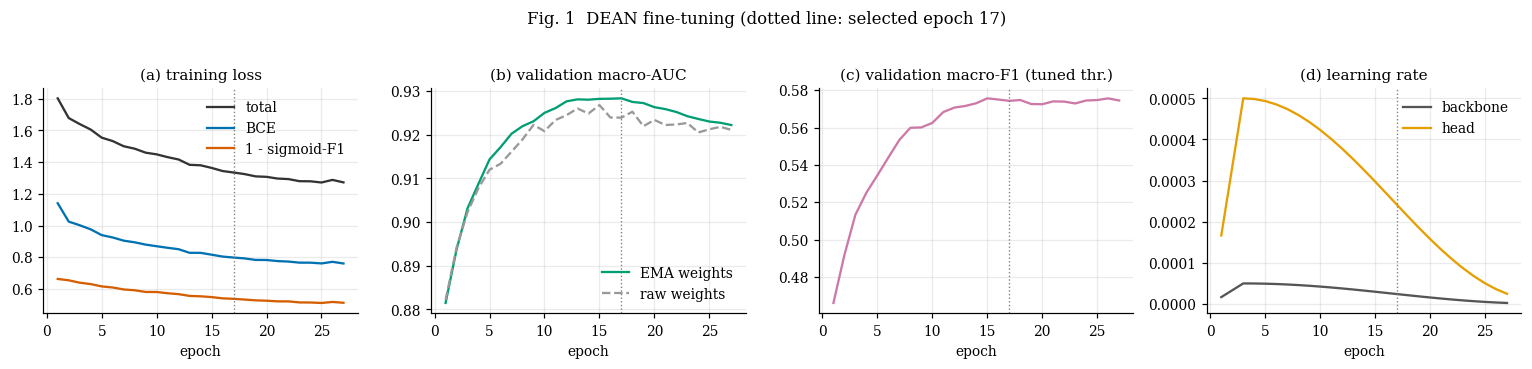

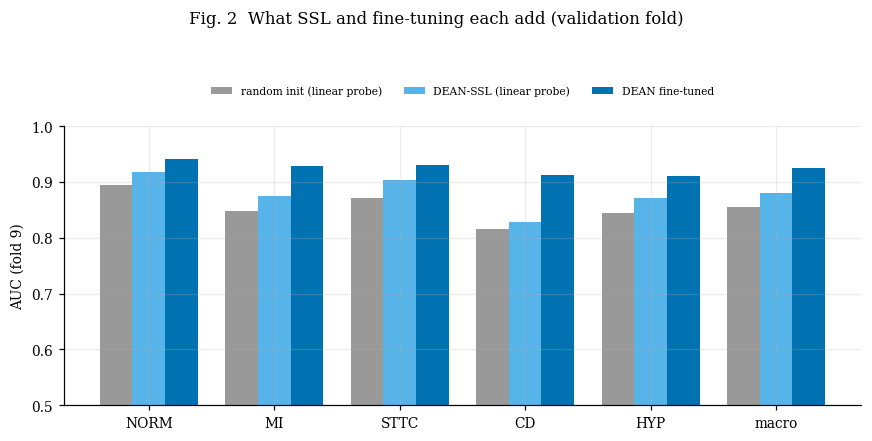

In [13]:
best_ep = result['best_epoch']
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
ax = axes[0]
ax.plot(hist.epoch, hist.loss, color='#333', label='total'); ax.plot(hist.epoch, hist.bce, color='#0072B2', label='BCE')
ax.plot(hist.epoch, hist.f1_loss, color='#D55E00', label='1 - sigmoid-F1'); ax.legend(); ax.set_title('(a) training loss')
axes[1].plot(hist.epoch, hist.val_macro_auc, color='#009E73', label='EMA weights')
axes[1].plot(hist.epoch, hist.val_auc_raw_weights, color='#999999', ls='--', label='raw weights'); axes[1].legend()
axes[1].set_title('(b) validation macro-AUC')
axes[2].plot(hist.epoch, hist.val_macro_f1, color='#CC79A7'); axes[2].set_title('(c) validation macro-F1 (tuned thr.)')
axes[3].plot(hist.epoch, hist.lr_backbone, label='backbone', color='#555'); axes[3].plot(hist.epoch, hist.lr_head, label='head', color='#E69F00')
axes[3].set_title('(d) learning rate'); axes[3].legend()
for a in axes:
    a.set_xlabel('epoch'); a.axvline(best_ep, ls=':', color='gray', lw=0.9)
fig.suptitle(f'Fig. 1  DEAN fine-tuning (dotted line: selected epoch {best_ep})', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig01_finetune_curves')

methods = [('random init (linear probe)', '#999999'), ('DEAN-SSL (linear probe)', '#56B4E9'), ('DEAN fine-tuned', '#0072B2')]
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.26
auc_by = {'random init (linear probe)': auc_per_label(Yva, PROBE['random init']['S'], 1),
          'DEAN-SSL (linear probe)': auc_per_label(Yva, PROBE['DEAN-SSL']['S'], 1), 'DEAN fine-tuned': auc_per_label(Yva, S_ft, 1)}
for i, (nm, colr) in enumerate(methods):
    vals = list(auc_by[nm][:5]) + [BOOT[nm]['super_auc'][0]]
    ax.bar(np.arange(6) + (i - 1) * w, vals, w, label=nm, color=colr)
ax.set_xticks(range(6)); ax.set_xticklabels(SUPER + ['macro']); ax.set_ylim(0.5, 1.0); ax.set_ylabel('AUC (fold 9)')
ax.legend(fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.18))
fig.suptitle('Fig. 2  What SSL and fine-tuning each add (validation fold)', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig02_probe_vs_finetune')

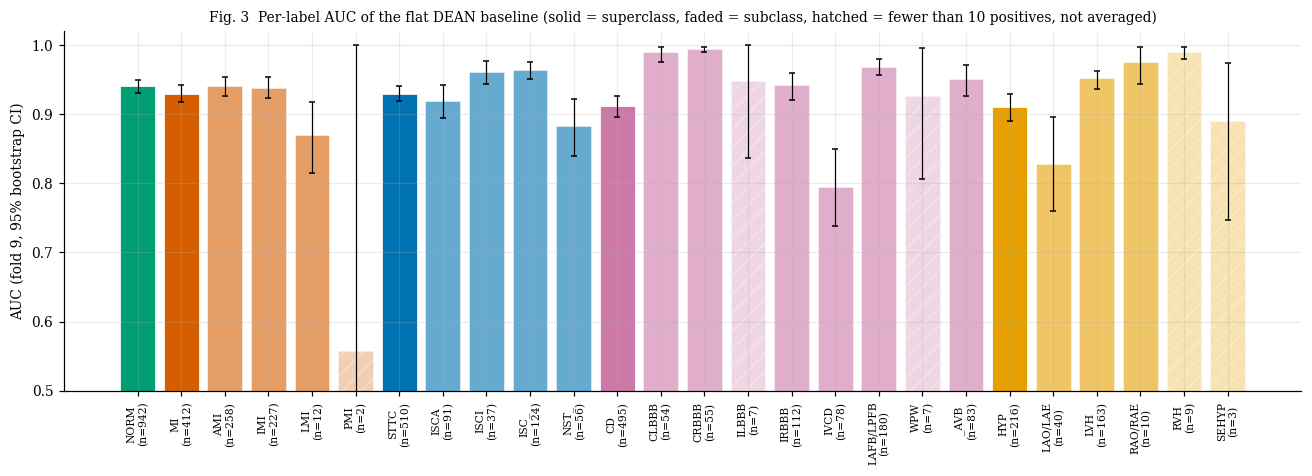

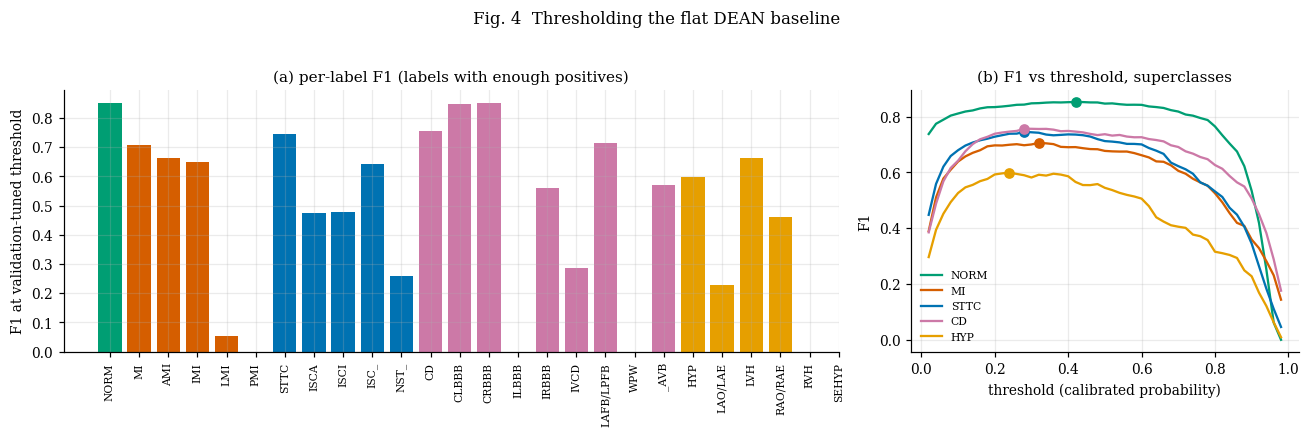

In [14]:
# per-label AUC with bootstrap intervals, grouped by family; hatched = fewer than min_pos_select positives
order = [l for s in SUPER for l in [s] + [x for x in SUB if FAMILY[x] == s]]
idx = [LABELS.index(l) for l in order]
fig, ax = plt.subplots(figsize=(12, 4.4))
for k, j in enumerate(idx):
    lab = LABELS[j]
    fam = lab if lab in SUPER else FAMILY[lab]
    a, lo, hi = PL.auc[j], PL.auc_lo[j], PL.auc_hi[j]
    if not np.isfinite(a):
        continue
    few = PL.n_pos[j] < CFG['min_pos_select']
    ax.bar(k, a, color=SUPER_COL[fam], alpha=0.3 if few else (1.0 if lab in SUPER else 0.6), hatch='//' if few else None,
           edgecolor='white', lw=0.5)
    ax.errorbar(k, a, yerr=[[max(a - lo, 0)], [max(hi - a, 0)]], color='k', lw=0.8, capsize=2)
ax.set_xticks(range(len(idx))); ax.set_xticklabels([f'{LABELS[j]}\n(n={int(PL.n_pos[j])})' for j in idx], rotation=90, fontsize=7)
ax.set_ylim(0.5, 1.02); ax.set_ylabel('AUC (fold 9, 95% bootstrap CI)'); ax.axhline(0.5, color='k', lw=0.6)
ax.set_title('Fig. 3  Per-label AUC of the flat DEAN baseline (solid = superclass, faded = subclass, hatched = fewer than %d positives, not averaged)' % CFG['min_pos_select'], fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig03_per_label_auc')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1]})
ok = PL.reliable.values
axes[0].bar(range(len(idx)), [PL.f1[j] if ok[j] else np.nan for j in idx], color=[SUPER_COL[LABELS[j] if LABELS[j] in SUPER else FAMILY[LABELS[j]]] for j in idx])
axes[0].set_xticks(range(len(idx))); axes[0].set_xticklabels([LABELS[j] for j in idx], rotation=90, fontsize=7)
axes[0].set_ylabel('F1 at validation-tuned threshold'); axes[0].set_title('(a) per-label F1 (labels with enough positives)')
for g, s in enumerate(SUPER):
    j = LABELS.index(s)
    grid = eval_lib.THR_GRID
    f = [f1_at(Yva[:, j:j + 1], S_ft[:, j:j + 1], [t])[0] for t in grid]
    axes[1].plot(grid, f, color=SUPER_COL[s], label=s)
    axes[1].plot(THR[j], PL.f1[j], 'o', color=SUPER_COL[s])
axes[1].set_xlabel('threshold (calibrated probability)'); axes[1].set_ylabel('F1'); axes[1].legend(fontsize=7); axes[1].set_title('(b) F1 vs threshold, superclasses')
fig.suptitle('Fig. 4  Thresholding the flat DEAN baseline', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig04_f1_and_thresholds')

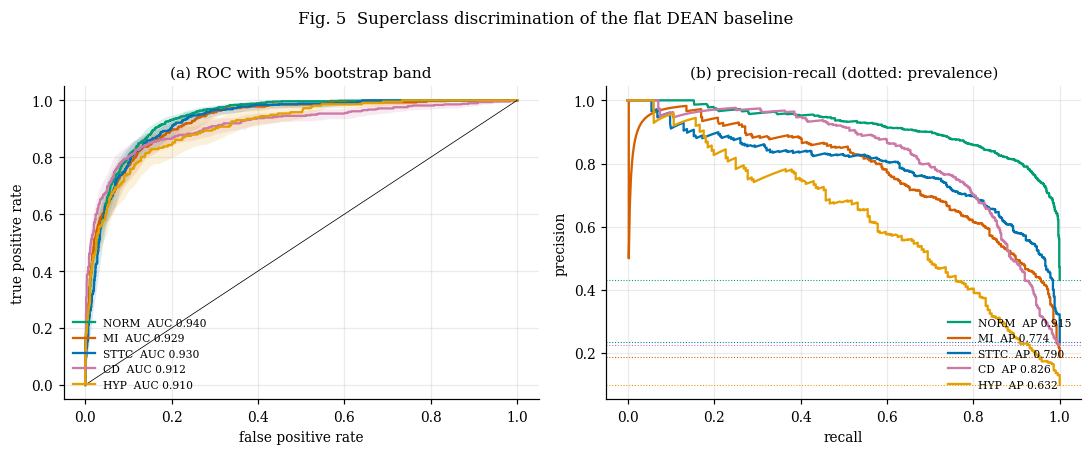

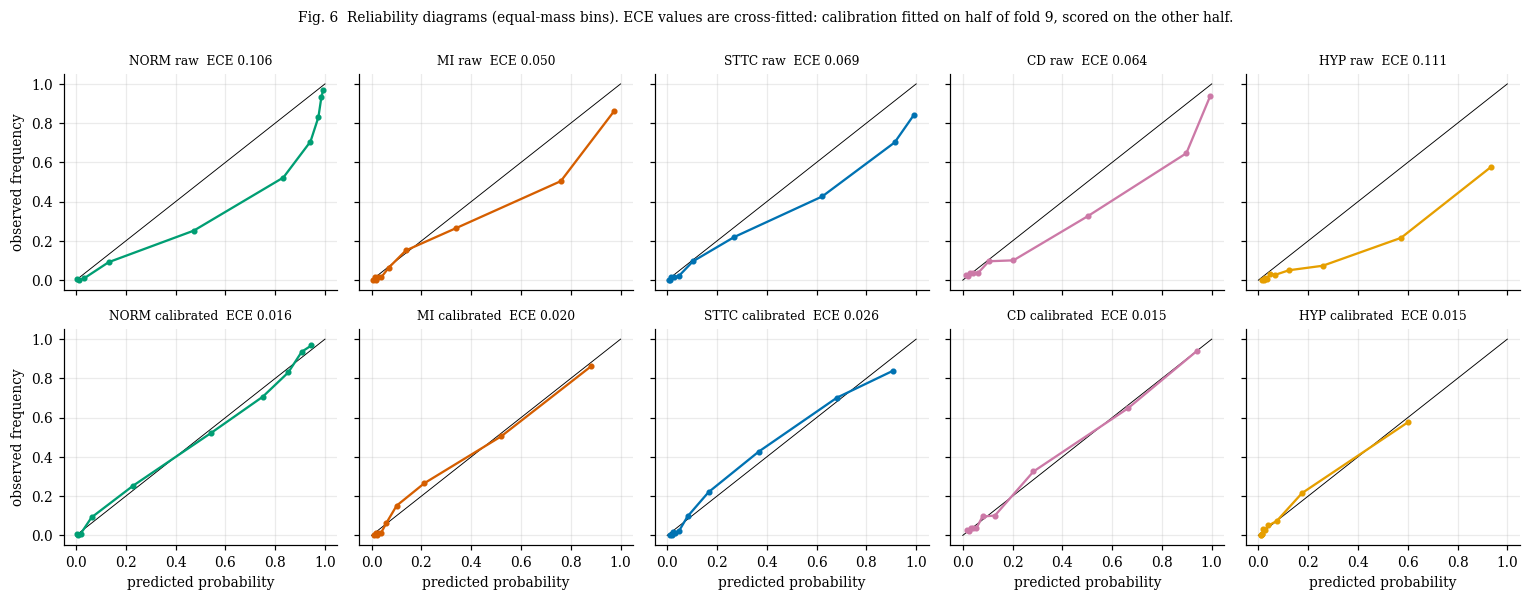

In [15]:
# ROC (with bootstrap band) and precision-recall for the superclasses
from sklearn.metrics import roc_curve, precision_recall_curve
fpr_grid = np.linspace(0, 1, 101)
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for s in SUPER:
    j = LABELS.index(s)
    f, t, _ = roc_curve(Yva[:, j], S_ft[:, j])
    tp_boot = []
    for _ in range(150):
        ii = rng.integers(0, len(Yva), len(Yva))
        if Yva[ii, j].sum() in (0, len(ii)):
            continue
        fb, tb, _ = roc_curve(Yva[ii, j], S_ft[ii, j])
        tp_boot.append(np.interp(fpr_grid, fb, tb))
    lo, hi = np.percentile(tp_boot, [2.5, 97.5], axis=0)
    axes[0].plot(f, t, color=SUPER_COL[s], label=f'{s}  AUC {PL.auc[j]:.3f}')
    axes[0].fill_between(fpr_grid, lo, hi, color=SUPER_COL[s], alpha=0.15, lw=0)
    p, r, _ = precision_recall_curve(Yva[:, j], S_ft[:, j])
    axes[1].plot(r, p, color=SUPER_COL[s], label=f'{s}  AP {PL.ap[j]:.3f}')
    axes[1].axhline(Yva[:, j].mean(), color=SUPER_COL[s], ls=':', lw=0.7)
axes[0].plot([0, 1], [0, 1], color='k', lw=0.5)
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate'); axes[0].set_title('(a) ROC with 95% bootstrap band')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('(b) precision-recall (dotted: prevalence)')
for a in axes: a.legend(fontsize=7, loc='lower left' if a is axes[0] else 'lower right')
fig.suptitle('Fig. 5  Superclass discrimination of the flat DEAN baseline', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig05_roc_pr_superclass')

# calibration before and after Platt scaling (curves use fold 9 itself, the ECE in the title is cross-fitted)
fig, axes = plt.subplots(2, 5, figsize=(14, 5.4), sharex=True, sharey=True)
for c_, s in enumerate(SUPER):
    j = LABELS.index(s)
    for r_, (Sx, nm) in enumerate([(S_raw[:, j], 'raw'), (S_ft[:, j], 'calibrated')]):
        ax = axes[r_, c_]
        conf, accu, _ = reliability(Yva[:, j], Sx, bins=10)
        ax.plot([0, 1], [0, 1], color='k', lw=0.6); ax.plot(conf, accu, 'o-', color=SUPER_COL[s], ms=3)
        e = ece_raw[j] if r_ == 0 else ece_cal[j]
        ax.set_title(f'{s} {nm}  ECE {e:.3f}', fontsize=8)
        if r_ == 1: ax.set_xlabel('predicted probability')
    axes[0, 0].set_ylabel('observed frequency'); axes[1, 0].set_ylabel('observed frequency')
fig.suptitle('Fig. 6  Reliability diagrams (equal-mass bins). ECE values are cross-fitted: calibration fitted on half of fold 9, scored on the other half.', y=1.0, fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig06_calibration')

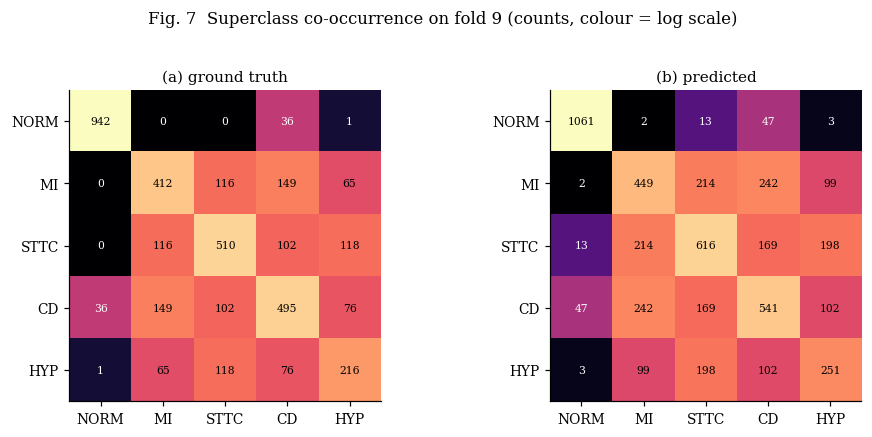

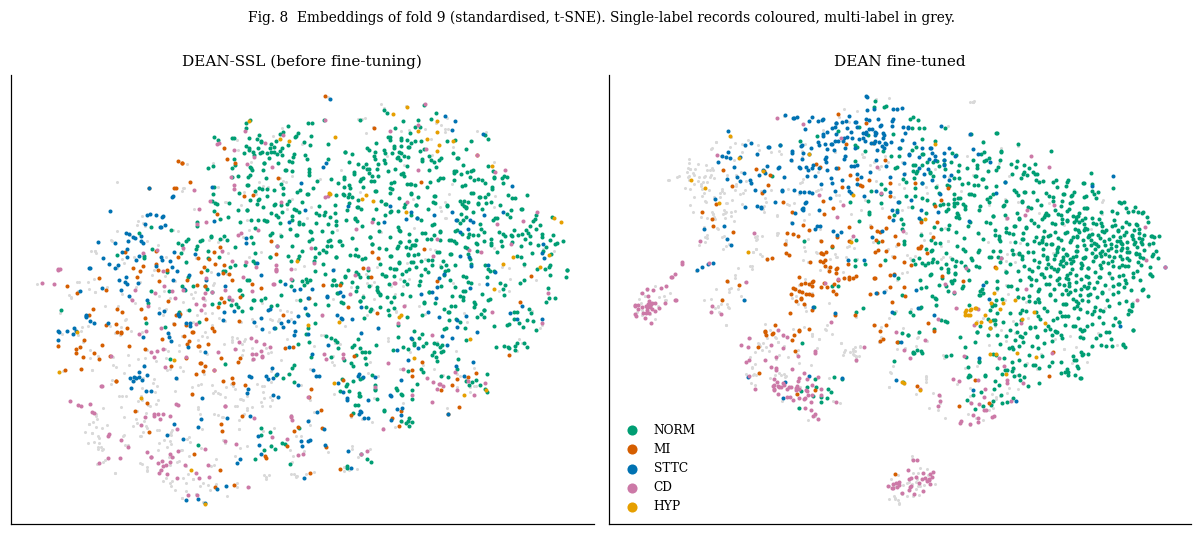

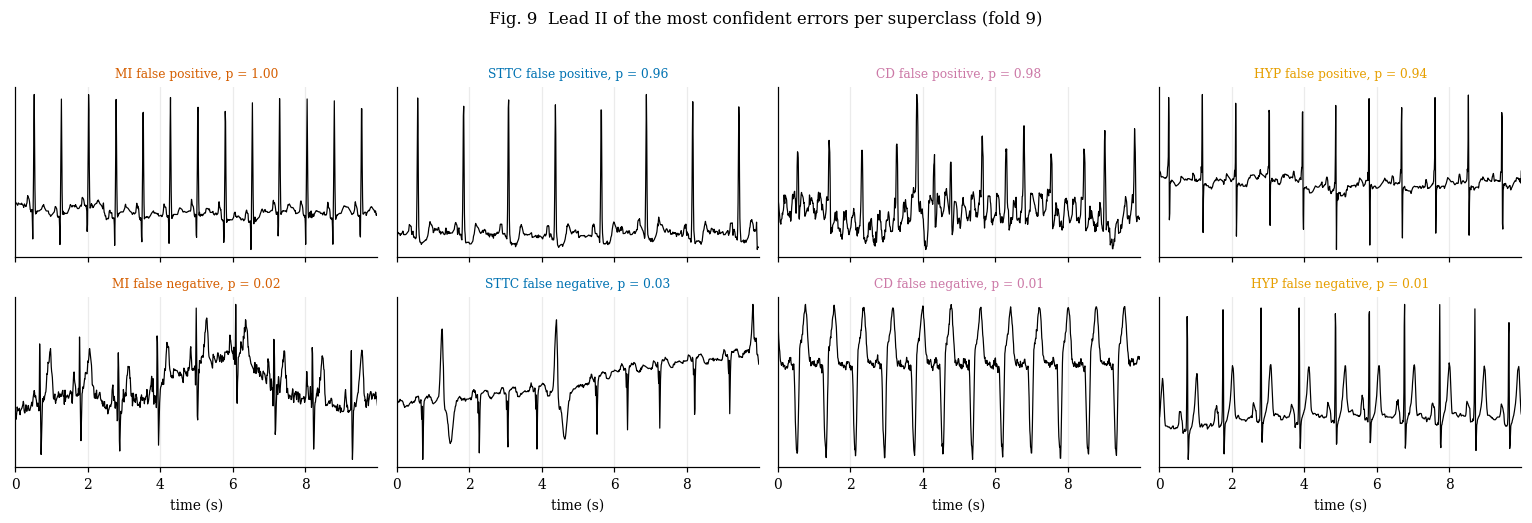

In [16]:
# co-occurrence of superclasses: truth vs prediction, and t-SNE before / after fine-tuning
pred_sup = (S_ft[:, :5] >= THR[:5][None]).astype(float)
co_true, co_pred = Yva[:, :5].T @ Yva[:, :5], pred_sup.T @ pred_sup
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, ttl in [(axes[0], co_true, '(a) ground truth'), (axes[1], co_pred, '(b) predicted')]:
    ax.imshow(np.log1p(M), cmap='magma'); ax.grid(False)
    for a_ in range(5):
        for b_ in range(5):
            ax.text(b_, a_, int(M[a_, b_]), ha='center', va='center', fontsize=7, color='w' if np.log1p(M[a_, b_]) < 0.6 * np.log1p(M.max()) else 'k')
    ax.set_xticks(range(5)); ax.set_xticklabels(SUPER); ax.set_yticks(range(5)); ax.set_yticklabels(SUPER); ax.set_title(ttl)
fig.suptitle('Fig. 7  Superclass co-occurrence on fold 9 (counts, colour = log scale)', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig07_cooccurrence')

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
sup_n = Yva[:, :5].sum(1)
prim = Yva[:, :5].argmax(1)
single = np.where(sup_n == 1)[0]
def tsne_xy(Zn):
    Zn = (Zn - Zn.mean(0)) / (Zn.std(0) + 1e-6)
    k = min(50, Zn.shape[1], Zn.shape[0] - 1)
    Zp = PCA(n_components=k, random_state=0).fit_transform(Zn)
    return TSNE(n_components=2, perplexity=min(30, len(Zn) // 4), init='pca', learning_rate='auto', random_state=0).fit_transform(Zp)
XY = {'DEAN-SSL (before fine-tuning)': tsne_xy(Z['DEAN-SSL'][1].cpu().numpy()), 'DEAN fine-tuned': tsne_xy(emb_va)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (nm, xy) in zip(axes, XY.items()):
    ax.scatter(xy[:, 0], xy[:, 1], s=4, c='#d9d9d9', lw=0)
    for j, s in enumerate(SUPER):
        ii = single[prim[single] == j]
        ax.scatter(xy[ii, 0], xy[ii, 1], s=7, color=SUPER_COL[s], lw=0, label=s)
    ax.set_title(nm); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[1].legend(markerscale=2.5, fontsize=8)
fig.suptitle('Fig. 8  Embeddings of fold 9 (standardised, t-SNE). Single-label records coloured, multi-label in grey.', y=1.0, fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig08_tsne_before_after')

# most confident mistakes, as a sanity check that the model fails for understandable reasons
Xva_np = DATA['X_va'].cpu().numpy()
show = ['MI', 'STTC', 'CD', 'HYP']
fig, axes = plt.subplots(2, 4, figsize=(14, 4.6), sharex=True)
t = np.arange(Xva_np.shape[2]) / 100
for c_, s in enumerate(show):
    j = LABELS.index(s)
    neg, pos = np.where(Yva[:, j] == 0)[0], np.where(Yva[:, j] == 1)[0]
    fp_i = neg[np.argmax(S_ft[neg, j])]
    fn_i = pos[np.argmin(S_ft[pos, j])]
    for r_, (i_, kind) in enumerate([(fp_i, 'false positive'), (fn_i, 'false negative')]):
        ax = axes[r_, c_]
        ax.plot(t, Xva_np[i_, 1] * SD[1] + MU[1], color='k', lw=0.8)
        ax.set_title(f'{s} {kind}, p = {S_ft[i_, j]:.2f}', fontsize=8, color=SUPER_COL[s])
        ax.set_yticks([]); ax.margins(x=0)
for ax in axes[-1]: ax.set_xlabel('time (s)')
fig.suptitle('Fig. 9  Lead II of the most confident errors per superclass (fold 9)', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig09_error_examples')

## 12. Does SSL still help after fine-tuning? (random-init baseline)
The probe comparison only shows that SSL helps a frozen encoder. A reviewer will ask whether it helps once everything is trained. Here the same fine-tuning run, with exactly the same configuration, starts from the random-init encoder of section 8 and its own probe head. The difference between the two runs is the value of NB-01, and it also supplies the "without SSL" row for the ablation notebook.

Validation predictions are saved to `randft_val_logits.npy`, so a later session can skip this stage. It is skipped as well when `run_random_ft=False` or when the time budget is already used up.

In [17]:
RANDFT = None
if CFG['run_random_ft'] and not TIME_UP:
    cached = find_art('randft_val_logits.npy')
    if cached:
        RANDFT = dict(logits=np.load(cached), best_epoch=None)
        print('random-init fine-tune already done, loaded', cached)
    else:
        res_r = run_finetune(CFG, DATA, CKPT_DIR, RAND_STATE, PROBE['random init']['head'],
                             resume_path=find_art('ft_randinit_last.pt'), tag='randinit')
        if res_r['stopped_early']:
            TIME_UP = True
            print('Paused. Publish the output as a Dataset and re-run to continue this stage.')
        else:
            lg_r, _ = predict(res_r['model'], DATA['X_va'])
            np.save(os.path.join(WORK, 'randft_val_logits.npy'), lg_r)
            pd.DataFrame(res_r['history']).to_csv(os.path.join(WORK, 'randft_history.csv'), index=False)
            RANDFT = dict(logits=lg_r, best_epoch=res_r['best_epoch'])
            del res_r
            torch.cuda.empty_cache()
else:
    print('random-init fine-tune skipped')

[randinit] epoch 1/30:   0%|          | 0/544 [00:00<?, ?it/s]

[randinit] ep  1 | loss 1.9358 (bce 1.2309, f1 0.705) | val AUC ema 0.8540 raw 0.8538 F1 0.4270 |   306s | best


[randinit] epoch 2/30:   0%|          | 0/544 [00:00<?, ?it/s]

[randinit] ep  2 | loss 1.8457 (bce 1.1578, f1 0.688) | val AUC ema 0.8710 raw 0.8717 F1 0.4445 |   313s | best


[randinit] epoch 3/30:   0%|          | 0/544 [00:00<?, ?it/s]

[randinit] ep  3 | loss 1.7944 (bce 1.1186, f1 0.676) | val AUC ema 0.8841 raw 0.8795 F1 0.4665 |   306s | best


... (46 outputs left out)

[randinit] epoch 27/30:   0%|          | 0/544 [00:00<?, ?it/s]

[randinit] ep 27 | loss 1.3500 (bce 0.8070, f1 0.543) | val AUC ema 0.9222 raw 0.9222 F1 0.5719 |   344s


[randinit] epoch 28/30:   0%|          | 0/544 [00:00<?, ?it/s]

[randinit] ep 28 | loss 1.3381 (bce 0.7991, f1 0.539) | val AUC ema 0.9223 raw 0.9221 F1 0.5727 |   347s
[randinit] no improvement for 10 epochs, stopping at epoch 28


                                  superclass AUC          subclass AUC       macro AUC (all) macro F1 (val-tuned thr.)
random init (linear probe)  0.855 [0.844, 0.864]  0.847 [0.832, 0.860]  0.849 [0.837, 0.860]      0.419 [0.395, 0.443]
DEAN-SSL (linear probe)     0.880 [0.870, 0.888]  0.878 [0.865, 0.891]  0.879 [0.868, 0.889]      0.461 [0.441, 0.480]
random init (fine-tuned)    0.918 [0.910, 0.926]  0.925 [0.916, 0.933]  0.924 [0.916, 0.930]      0.564 [0.538, 0.587]
DEAN fine-tuned             0.925 [0.917, 0.932]  0.930 [0.921, 0.937]  0.929 [0.921, 0.935]      0.572 [0.546, 0.598]
macro-AUC gain of SSL init over random init, both fine-tuned (paired bootstrap): 0.005 [0.000, 0.009]


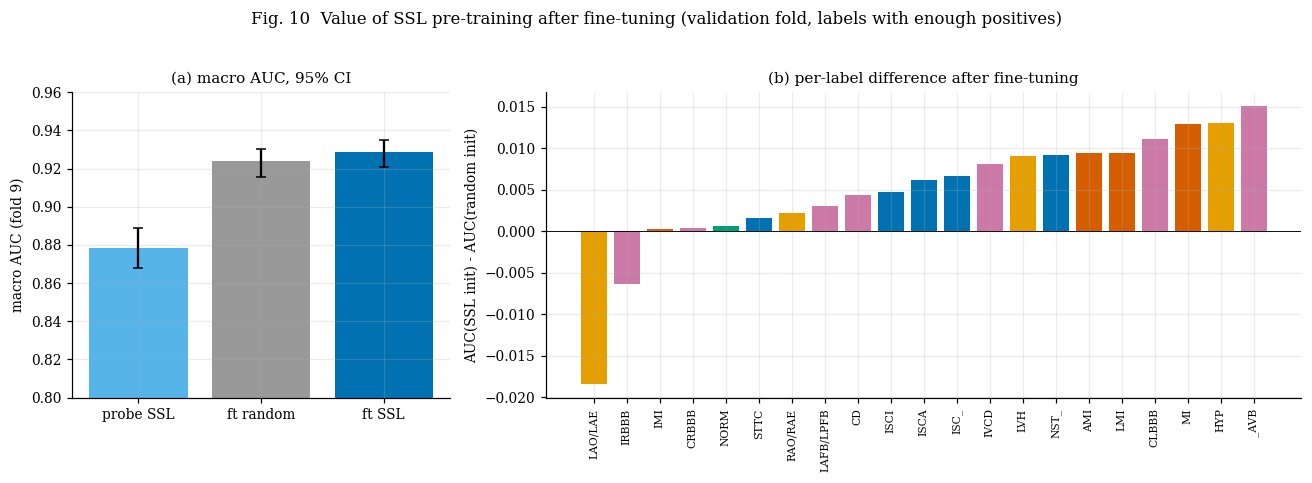

In [18]:
if RANDFT is not None:
    lg_r = RANDFT['logits']
    a_r, b_r = fit_calibration(lg_r, Yva, CFG['min_pos_select'])      # same calibration recipe, for a like-for-like F1
    S_r = sigmoid(lg_r * a_r + b_r)
    thr_r, _ = tune_thresholds(Yva, S_r)
    BOOT['random init (fine-tuned)'] = bootstrap(Yva, S_r, thr_r, CFG['min_pos_report'], CFG['n_boot'])
    cmp_tab = make_cmp_tab()
    print(cmp_tab.to_string())

    d_ssl = paired_delta(Yva, S_ft, S_r, CFG['min_pos_report'], CFG['n_boot'])
    print('macro-AUC gain of SSL init over random init, both fine-tuned (paired bootstrap): %.3f [%.3f, %.3f]' % tuple(d_ssl))
    ablation = pd.DataFrame({'macro_auc_gain_ssl_over_random_ft': d_ssl,
                             'macro_auc_gain_ft_over_probe': d_probe}, index=['mean', 'ci_lo', 'ci_hi']).T
    ablation.to_csv(os.path.join(WORK, 'ablation_ssl.csv'))

    auc_s, auc_r = auc_per_label(Yva, S_ft, 1), auc_per_label(Yva, S_r, 1)
    rel = [j for j in range(len(LABELS)) if n_pos_va[j] >= CFG['min_pos_select']]
    rel = sorted(rel, key=lambda j: auc_s[j] - auc_r[j])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1, 2]})
    ax = axes[0]
    names = ['probe SSL', 'ft random', 'ft SSL']
    vals = [BOOT['DEAN-SSL (linear probe)']['macro_auc'], BOOT['random init (fine-tuned)']['macro_auc'], BOOT['DEAN fine-tuned']['macro_auc']]
    ax.bar(range(3), [v[0] for v in vals], color=['#56B4E9', '#999999', '#0072B2'],
           yerr=[[max(v[0] - v[1], 0) for v in vals], [max(v[2] - v[0], 0) for v in vals]], capsize=3)
    ax.set_xticks(range(3)); ax.set_xticklabels(names); ax.set_ylim(0.8, 0.96); ax.set_ylabel('macro AUC (fold 9)')
    ax.set_title('(a) macro AUC, 95% CI')
    axes[1].bar(range(len(rel)), [auc_s[j] - auc_r[j] for j in rel],
                color=[SUPER_COL[LABELS[j] if LABELS[j] in SUPER else FAMILY[LABELS[j]]] for j in rel])
    axes[1].axhline(0, color='k', lw=0.6)
    axes[1].set_xticks(range(len(rel))); axes[1].set_xticklabels([LABELS[j] for j in rel], rotation=90, fontsize=7)
    axes[1].set_ylabel('AUC(SSL init) - AUC(random init)'); axes[1].set_title('(b) per-label difference after fine-tuning')
    fig.suptitle('Fig. 10  Value of SSL pre-training after fine-tuning (validation fold, labels with enough positives)', y=1.03)
    fig.tight_layout()
    save_fig(fig, 'fig10_ssl_ablation')
else:
    print('no random-init fine-tune available, ablation figure skipped')

## 13. Out-of-fold teacher predictions
The final teacher has seen the 17,418 training records many times, so its logits on them are sharper than its logits on new data. A student distilled from those logits would imitate a more confident teacher than the one we evaluate. To avoid that, the training records are split into four groups of two folds, (1,2), (3,4), (5,6) and (7,8). For each group a fresh model is fine-tuned on the other six folds and predicts the held-out group. Every training record then has a logit from a model that never saw it.

Each model uses the same recipe as the main run, only shorter (`oof_epochs`, schedule compressed accordingly), and it is selected on fold 9 like the main one. Its linear probe is refitted on its own training folds, so no held-out label reaches the initial head. The SSL encoder itself never used labels, so it is shared. The OOF models are only used to produce logits. The deployable teacher is still the main model.

Each finished group is saved as `oof_group<k>.npz`, so a later session picks up where this one stopped.

In [19]:
OOF_GROUPS = [(1, 2), (3, 4), (5, 6), (7, 8)]
OOF_DONE = False
if CFG['run_oof'] and not TIME_UP:
    c_oof = dict(CFG)
    c_oof.update(epochs=CFG['oof_epochs'], patience=CFG['oof_patience'], warmup_epochs=1)
    for k, g in enumerate(OOF_GROUPS):
        if find_art(f'oof_group{k}.npz'):
            print(f'group {k} {g}: already done')
            continue
        held = torch.from_numpy(np.isin(fold_tr, g)).to(dev)
        print(f'group {k} {g}: train on {int((~held).sum())}, predict {int(held.sum())}')
        sub = dict(X_tr=DATA['X_tr'][~held], Y_tr=DATA['Y_tr'][~held], X_va=DATA['X_va'], Y_va=Yva)
        hs_k, _, _, _ = train_probe(Z['DEAN-SSL'][0][~held], sub['Y_tr'], Z['DEAN-SSL'][1], Yva, c_oof)
        res_k = run_finetune(c_oof, sub, CKPT_DIR, ssl_ckpt[SSL_KEY], hs_k, resume_path=find_art(f'ft_oof{k}_last.pt'), tag=f'oof{k}')
        if res_k['stopped_early']:
            TIME_UP = True
            print('Paused. Publish the output as a Dataset and re-run to continue.')
            break
        lg_k, _ = predict(res_k['model'], DATA['X_tr'][held])
        np.savez(os.path.join(WORK, f'oof_group{k}.npz'), idx=np.where(held.cpu().numpy())[0], logits=lg_k,
                 best_epoch=res_k['best_epoch'], val_auc=res_k['best_score'])
        print(f'group {k}: best epoch {res_k["best_epoch"]}, validation macro-AUC {res_k["best_score"]:.4f}')
        del sub, res_k, held
        torch.cuda.empty_cache()
else:
    print('out-of-fold stage skipped')

def load_oof():
    out = np.full((len(tr_idx), len(LABELS)), np.nan, dtype=np.float32)
    for k in range(len(OOF_GROUPS)):
        p = find_art(f'oof_group{k}.npz')
        if p is None:
            return None
        d = np.load(p)
        out[d['idx']] = d['logits']
    return out if np.isfinite(out).all() else None

LG_OOF = load_oof()
OOF_DONE = LG_OOF is not None
print('out-of-fold logits complete:', OOF_DONE)

group 0 (1, 2): train on 13062, predict 4356


[oof0] epoch 1/12:   0%|          | 0/408 [00:00<?, ?it/s]

[oof0] ep  1 | loss 1.7965 (bce 1.1341, f1 0.662) | val AUC ema 0.8823 raw 0.8818 F1 0.4723 |   263s | best


[oof0] epoch 2/12:   0%|          | 0/408 [00:00<?, ?it/s]

[oof0] ep  2 | loss 1.6671 (bce 1.0198, f1 0.647) | val AUC ema 0.8977 raw 0.8947 F1 0.4990 |   250s | best


[oof0] epoch 3/12:   0%|          | 0/408 [00:00<?, ?it/s]

... (87 outputs left out)

[oof3] epoch 11/12:   0%|          | 0/408 [00:00<?, ?it/s]

[oof3] ep 11 | loss 1.4384 (bce 0.8598, f1 0.579) | val AUC ema 0.9175 raw 0.9176 F1 0.5464 |   240s | best


[oof3] epoch 12/12:   0%|          | 0/408 [00:00<?, ?it/s]

[oof3] ep 12 | loss 1.4315 (bce 0.8553, f1 0.576) | val AUC ema 0.9176 raw 0.9176 F1 0.5471 |   239s | best
group 3: best epoch 12, validation macro-AUC 0.9176
out-of-fold logits complete: True


## 14. Teacher cache and the confidence gap
The cache is built from the final (EMA) teacher: 26-d logits, pooled 256-d embeddings and the final-layer token sequences (40 x 256, float16) for the training and validation records, in the row order of `split_idx.npz`. In NB-05 the token sequences are the targets of the Gram-RKD term. If the out-of-fold stage finished, the out-of-fold logits are saved as well, and the gap between in-sample, out-of-fold and validation predictions is measured here rather than assumed.

Token sequences are in-sample for the training records (there is no out-of-fold version of them). Relational losses depend on the geometry between samples, which is much less affected by over-confidence than a per-sample logit, but this is worth one sentence in the paper.

cache built in 36s | tokens (17418, 40, 256) float16
                     macro AUC  mean prob. on true positives  mean prob. on true negatives  superclass ECE (raw)
in-sample (train)        0.981                         0.907                         0.168                 0.074
out-of-fold (train)      0.927                         0.782                         0.209                 0.097
validation (fold 9)      0.928                         0.767                         0.182                 0.080


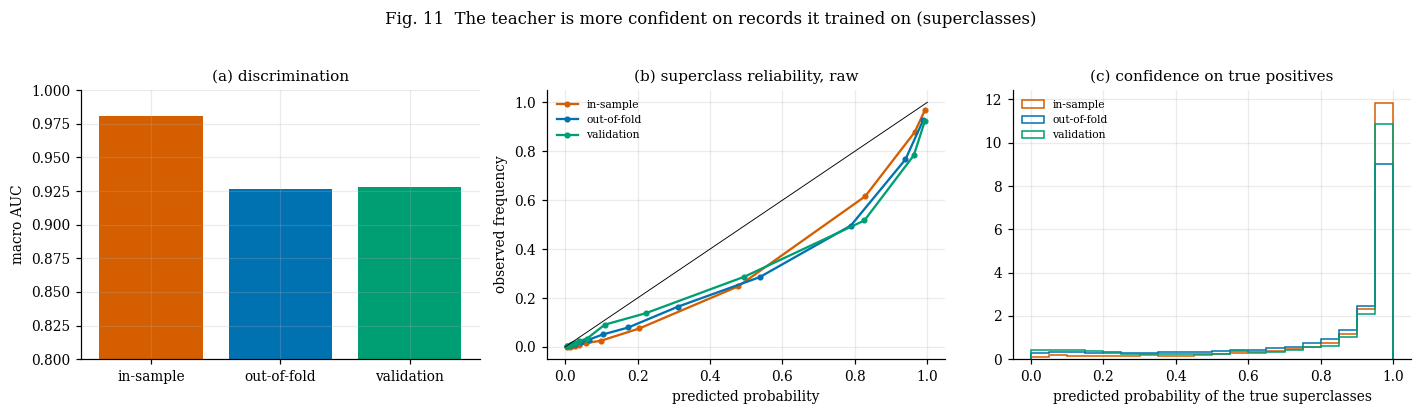

In [20]:
t0 = time.time()
lg_tr, em_tr, tk_tr = predict(model, DATA['X_tr'], tokens=True)
lg_va, em_va, tk_va = predict(model, DATA['X_va'], tokens=True)
print(f'cache built in {time.time() - t0:.0f}s | tokens {tk_tr.shape} {tk_tr.dtype}')
assert np.isfinite(lg_tr).all() and np.isfinite(tk_tr.astype(np.float32)).all()
assert np.allclose(lg_va, logits_va, atol=1e-3), 'cached validation logits differ from the evaluated ones'

Ytr_np = Ytr_t.cpu().numpy()
GAP = None
if OOF_DONE:
    ok = n_pos_va >= CFG['min_pos_select']
    def gap_row(lg, Y):
        S = sigmoid(lg)
        a = auc_per_label(Y, S, 1)
        sup = np.concatenate([reliability(Y[:, j], S[:, j], 10)[2:] for j in range(5)])
        return {'macro AUC': float(np.nanmean(a[ok])),
                'mean prob. on true positives': float(np.mean([S[Y[:, j] == 1, j].mean() for j in range(len(LABELS)) if ok[j]])),
                'mean prob. on true negatives': float(np.mean([S[Y[:, j] == 0, j].mean() for j in range(len(LABELS)) if ok[j]])),
                'superclass ECE (raw)': float(sup.mean())}
    GAP = pd.DataFrame({'in-sample (train)': gap_row(lg_tr, Ytr_np), 'out-of-fold (train)': gap_row(LG_OOF, Ytr_np),
                        'validation (fold 9)': gap_row(lg_va, Yva)}).T
    print(GAP.round(3).to_string())
    GAP.to_csv(os.path.join(WORK, 'teacher_confidence_gap.csv'))

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
    cols = ['#D55E00', '#0072B2', '#009E73']
    axes[0].bar(range(3), GAP['macro AUC'], color=cols); axes[0].set_xticks(range(3)); axes[0].set_xticklabels(['in-sample', 'out-of-fold', 'validation'])
    axes[0].set_ylim(0.8, 1.0); axes[0].set_ylabel('macro AUC'); axes[0].set_title('(a) discrimination')
    for (lg, Y, nm), c_ in zip([(lg_tr, Ytr_np, 'in-sample'), (LG_OOF, Ytr_np, 'out-of-fold'), (lg_va, Yva, 'validation')], cols):
        S = sigmoid(lg[:, :5]).ravel(); T = Y[:, :5].ravel()
        conf, accu, _ = reliability(T, S, 12)
        axes[1].plot(conf, accu, 'o-', color=c_, ms=3, label=nm)
        axes[2].hist(S[T == 1], bins=np.linspace(0, 1, 21), histtype='step', color=c_, density=True, label=nm)
    axes[1].plot([0, 1], [0, 1], color='k', lw=0.6); axes[1].set_xlabel('predicted probability'); axes[1].set_ylabel('observed frequency')
    axes[1].set_title('(b) superclass reliability, raw'); axes[1].legend(fontsize=7)
    axes[2].set_xlabel('predicted probability of the true superclasses'); axes[2].set_title('(c) confidence on true positives'); axes[2].legend(fontsize=7)
    fig.suptitle('Fig. 11  The teacher is more confident on records it trained on (superclasses)', y=1.03)
    fig.tight_layout()
    save_fig(fig, 'fig11_teacher_confidence_gap')
else:
    print('no out-of-fold logits, gap analysis skipped. Distillation notebooks must then use a temperature above 1.')

## 15. Export
DEAN is frozen from here on. Everything the later notebooks read from it is written below.

In [21]:
for nm, arr in [('dean_logits_train', lg_tr), ('dean_logits_val', lg_va), ('dean_emb_train', em_tr), ('dean_emb_val', em_va),
                ('dean_tokens_train_fp16', tk_tr), ('dean_tokens_val_fp16', tk_va)]:
    np.save(os.path.join(WORK, nm + '.npy'), arr)
if OOF_DONE:
    np.save(os.path.join(WORK, 'dean_logits_train_oof.npy'), LG_OOF)
np.savez(os.path.join(WORK, 'split_idx.npz'), train_idx=tr_idx, val_idx=va_idx, test_idx=te_idx,
         ecg_id_train=ecg_id[tr_idx], ecg_id_val=ecg_id[va_idx], fold_train=fold_tr, label_columns=np.array(LABELS))

calib = {'recipe': 'p = sigmoid(a * logit + b), per label, fitted on fold 9; labels with < %d positives share one pooled (a, b)' % CFG['min_pos_select'],
         'final_on_val': {'a': CAL_A.tolist(), 'b': CAL_B.tolist()},
         'thresholds_on_calibrated_probability': THR.tolist()}
if OOF_DONE:
    a_o, b_o = fit_calibration(LG_OOF, Ytr_np, CFG['min_pos_select'])
    calib['oof_on_train'] = {'a': a_o.tolist(), 'b': b_o.tolist()}
json.dump(calib, open(os.path.join(WORK, 'calibration.json'), 'w'), indent=2)

torch.save({
    'encoder': model.enc.state_dict(), 'head': model.head.state_dict(), 'enc_config': ENC_CFG,
    'label_columns': LABELS, 'calibration': {'a': CAL_A.tolist(), 'b': CAL_B.tolist()},
    'thresholds': THR.tolist(), 'norm_mean': MU.tolist(), 'norm_std': SD.tolist(),
    'weights': 'EMA, best epoch by validation macro-AUC', 'best_epoch': int(result['best_epoch']), 'ssl_source': ssl_path,
}, os.path.join(WORK, 'dean_finetuned.pt'))

metrics = {
    'note': 'validation fold only (fold 9). Calibration and thresholds were fitted on this fold, so F1 is optimistic. Test numbers come from NB-09.',
    'best_epoch': int(result['best_epoch']), 'epochs_run': int(len(hist)),
    'encoder_params_M': count_params(model.enc) / 1e6, 'head_params_K': count_params(model.head) / 1e3,
    'min_pos_report': CFG['min_pos_report'], 'unreliable_labels': UNRELIABLE,
    'bootstrap_95ci': {nm: {k: v for k, v in b.items() if not k.startswith('label_')} for nm, b in BOOT.items()},
    'probe_auc': probe_tab.to_dict(),
    'ece_crossfitted': {'raw': dict(zip(LABELS, np.nan_to_num(ece_raw, nan=-1).tolist())), 'calibrated': dict(zip(LABELS, np.nan_to_num(ece_cal, nan=-1).tolist()))},
    'paired_gain_ft_over_probe': d_probe,
    'paired_gain_ssl_over_random_ft': d_ssl if RANDFT is not None else None,
    'teacher_confidence_gap': GAP.round(4).to_dict(orient='index') if GAP is not None else None,
    'per_label': PL.round(4).to_dict(orient='records'),
}
json.dump(metrics, open(os.path.join(WORK, 'baseline_metrics.json'), 'w'), indent=2)
json.dump({'CFG': CFG, 'ENC_CFG': ENC_CFG, 'versions': VERSIONS, 'scan': 'unbind' if dean_lib.selective_scan is fast_scan else 'library',
           'labels': LABELS, 'train_folds': [1, 2, 3, 4, 5, 6, 7, 8], 'val_fold': 9,
           'random_ft_done': RANDFT is not None, 'oof_done': OOF_DONE, 'time_budget_hit': TIME_UP},
          open(os.path.join(WORK, 'dean_ft_config.json'), 'w'), indent=2)

shutil.rmtree(os.path.join(WORK, 'smoke_tmp'), ignore_errors=True)
print(f'total notebook time {(time.time() - NB_T0) / 3600:.2f} h')
print('files in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.tmp'):
            continue
        print(f'  {os.path.relpath(p, WORK):45s} {os.path.getsize(p) / 1e6:8.2f} MB')

total notebook time 8.33 h
files in /kaggle/working:
  __notebook__.ipynb                                1.49 MB
  ablation_ssl.csv                                  0.00 MB
  baseline_metrics.json                             0.01 MB
  calibration.json                                  0.00 MB
  dean_emb_train.npy                               17.84 MB
  dean_emb_val.npy                                  2.24 MB
  dean_finetuned.pt                                46.06 MB
  dean_ft_config.json                               0.00 MB
  dean_lib.py                                       0.01 MB
  dean_logits_train.npy                             1.81 MB
  dean_logits_train_oof.npy                         1.81 MB
  dean_logits_val.npy                               0.23 MB
  dean_tokens_train_fp16.npy                      356.72 MB
  dean_tokens_val_fp16.npy                         44.71 MB
  eval_lib.py                                       0.01 MB
  ft_history.csv                               

## 16. After this notebook
1. Save a version (Save & Run All), then create the Dataset **`dean-finetuned-v2`** from the output. The important files are `dean_finetuned.pt`, `calibration.json`, `baseline_metrics.json`, `eval_lib.py`, `dean_lib.py`, `split_idx.npz`, the cache arrays (including `dean_logits_train_oof.npy` if it exists) and `ablation_ssl.csv`. The `ckpt/` folder is only needed if a stage paused.
2. If a stage paused (the last lines of sections 9, 12 or 13 say so), publish the output as a Dataset, attach it, set `RUN_SMOKE = False` and run all again. Finished stages are detected from their saved files and skipped.
3. The numbers every later tier has to beat are the `DEAN fine-tuned` row of `val_metrics_table.csv`. Do not quote its F1 as a test result.
4. For distillation (NB-05 onwards) use `dean_logits_train_oof.npy` as the logit target on training records, converted with the `oof_on_train` entry of `calibration.json` if probabilities are needed. If that file does not exist, use a distillation temperature above 1 and say so in the paper.
5. Embedding dimension is 256, so the gate MLP in NB-03 has about 67K parameters, as recorded in the project notes.
6. Check three numbers before moving on: the gain of fine-tuning over the SSL probe, the gain of SSL init over random init after fine-tuning (both are paired-bootstrap intervals in section 10 and 12), and the confidence gap in section 14. If the SSL-over-random interval includes zero, report it as such and say that the benefit of NB-01 is not established.